## Aggregate into hexbins


Set path to include RStudio packages

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [2]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [ ]:
#gbif_try_glonaf2 <- fread("/net/scratch/swolf/GBIF/gbif_try6_s1_5000_glonaf_status.csv")
#gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/gbif_try6_CS_glonaf_status.csv")
#gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/GBIF_s1_5000_try6_GloNAF_WCVP_status_woody.csv")
gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/GBIF_try6_GloNAF_WCVP_status_woodiness_CS.csv")


head(gbif_try_glonaf)

## Optional: add urban data

In [ ]:
# read urban data result = pd.read_csv("/net/scratch/swolf/GBIF_urban_flags_2020.csv")
urban_data <- fread("/net/scratch/swolf/GBIF_urban_flags_2020.csv")


In [ ]:
dim(urban_data)

[1] 64141358        2

In [ ]:
head(urban_data)


gbifID,is_urban
<int64>,<lgl>
891018389,FALSE
891018395,FALSE
891018399,FALSE
891018400,FALSE
891018401,FALSE
891018402,FALSE


In [ ]:
# nuber of occurences per land_cover value in urban_data
table(urban_data$land_cover)


[1] "Number of urban occurrences: 146814"


In [8]:
# print rows where is_urban is not False
result <- merge(gbif_try_glonaf, urban_data[, .(gbifID, is_urban)], by="gbifID", all.x=TRUE)

In [9]:
result

ERROR: Error: object 'result' not found


## Some stats on the data

In [4]:
# remane "majority_status" to "status"
setnames(gbif_try_glonaf, old = "majority_status", new = "status")

In [5]:
dim(gbif_try_glonaf)

[1] 64141358       46

In [6]:
# number of NA in status
sum(is.na(gbif_try_glonaf$X.X3117.))

[1] 4311718

In [7]:
# if status is "" replace with NA
gbif_try_glonaf[status == "", status := NA]

In [8]:
# summary of status
table(gbif_try_glonaf$status, useNA = "ifany")


    native non-native       <NA> 
  51783950   11419062     938346 

In [9]:
# percentage of each status
prop.table(table(gbif_try_glonaf$status, useNA = "ifany"))


    native non-native       <NA> 
0.80734103 0.17802963 0.01462934 

In [10]:
# number of species in dataset
length(unique(gbif_try_glonaf$speciesKey)) 

length(unique(gbif_try_glonaf[status == "native"]$speciesKey)) 

# number of naturalized species in dataset
length(unique(gbif_try_glonaf[status == "non-native"]$speciesKey)) 


[1] 42520

[1] 41814

[1] 5521

## Distrubutions of traits

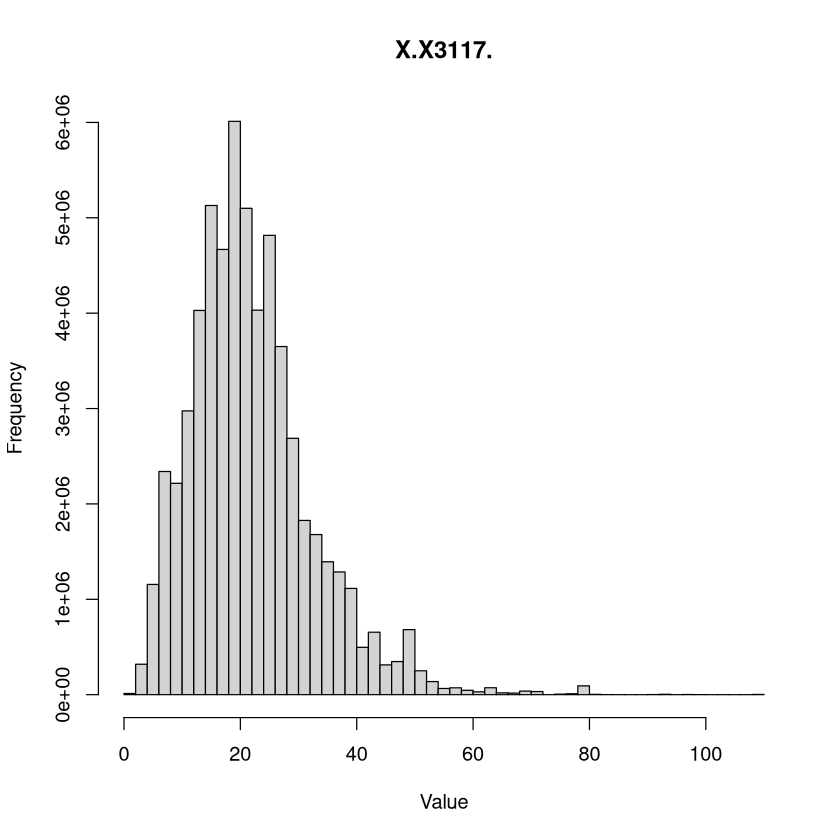

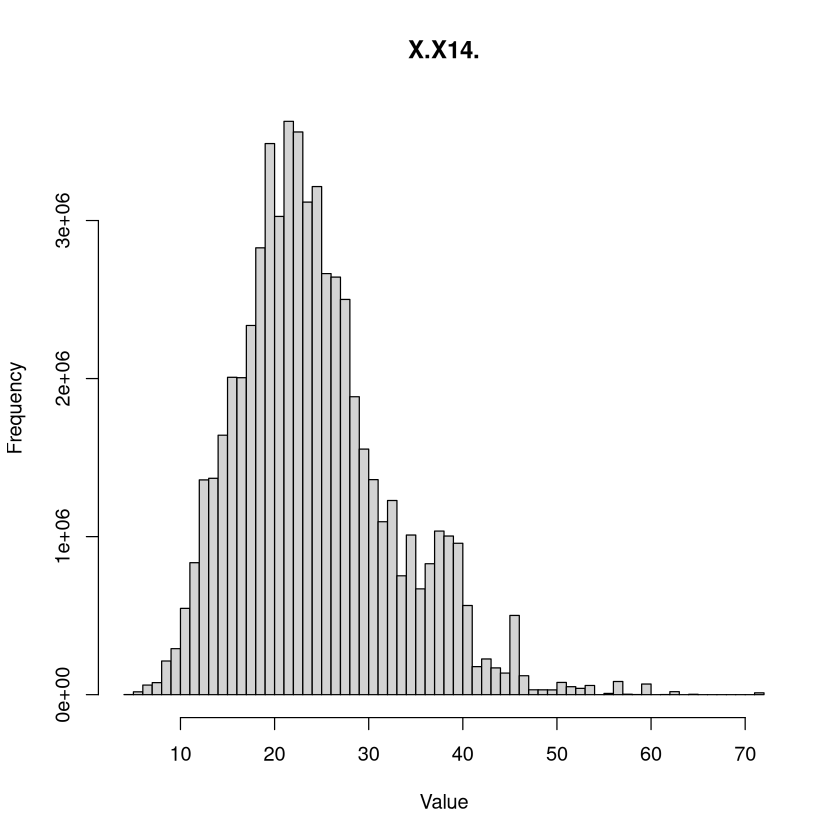

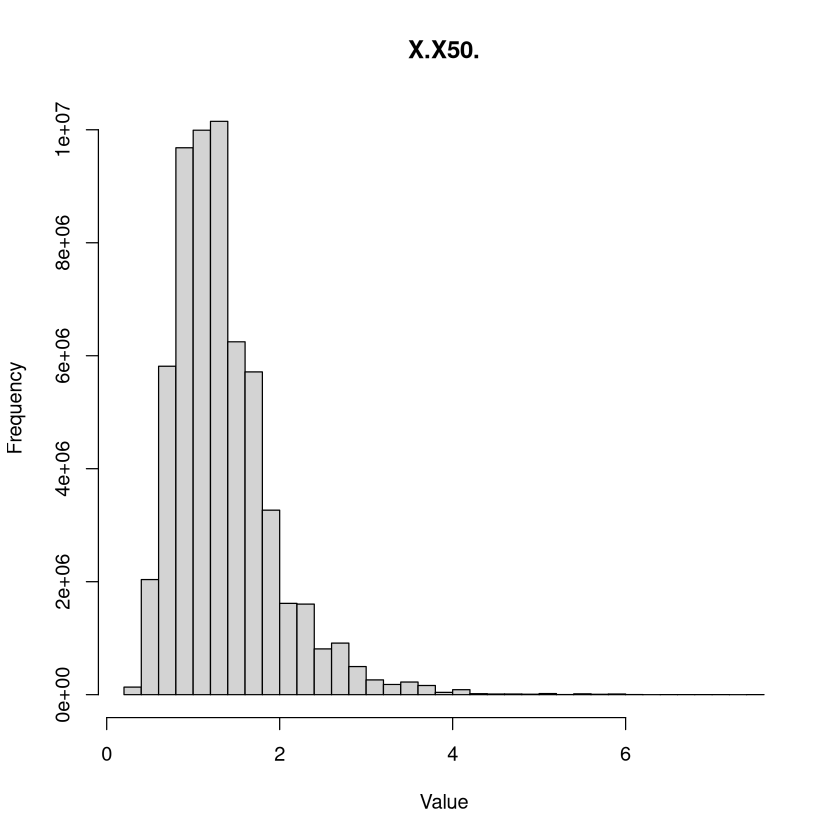

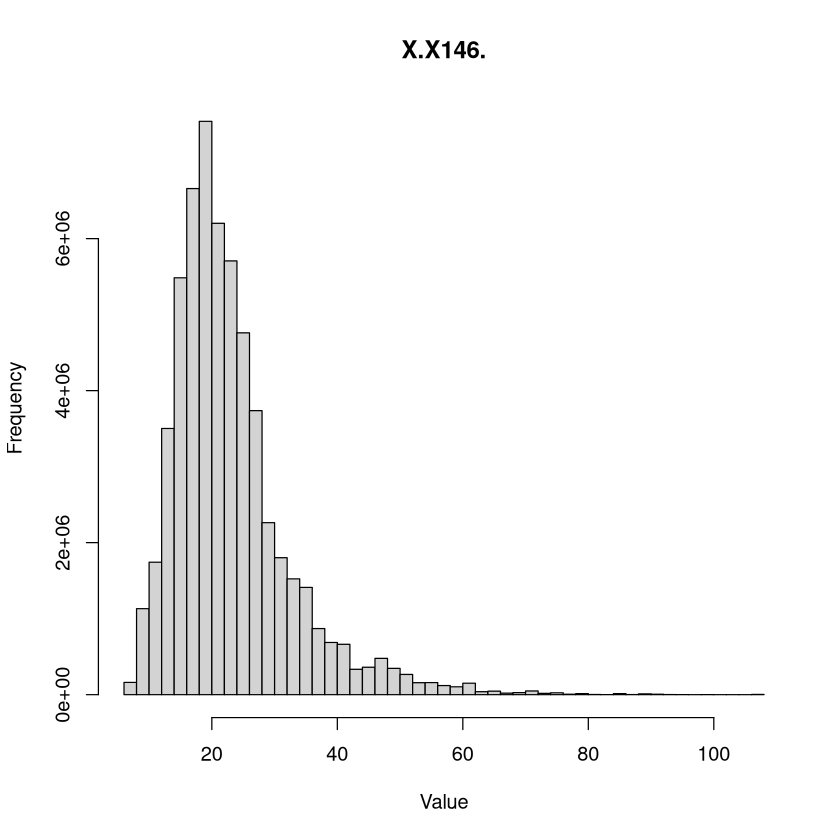

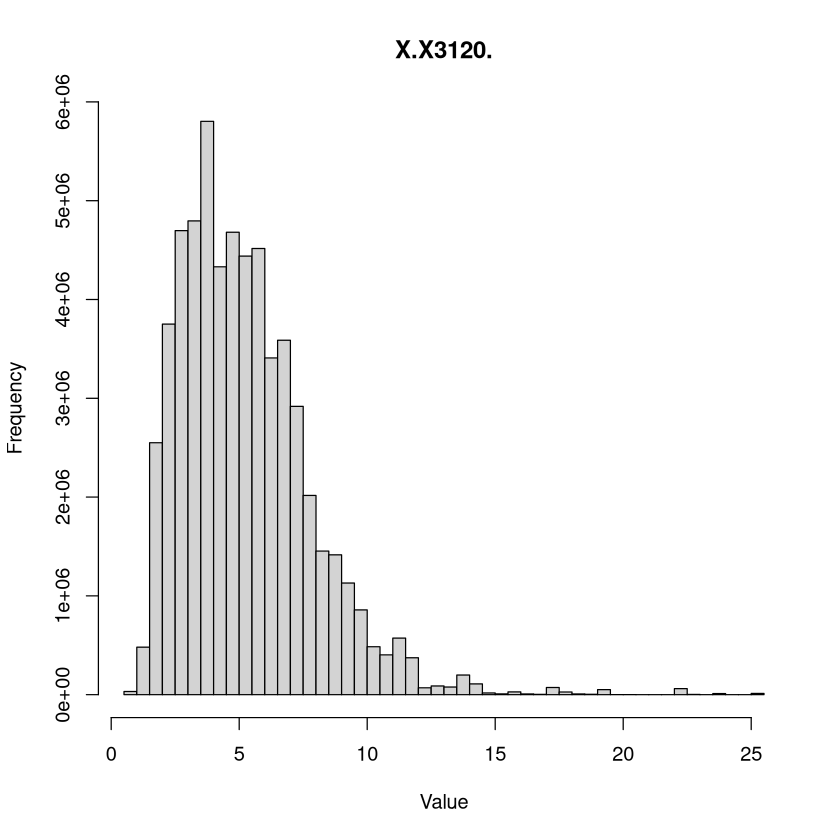

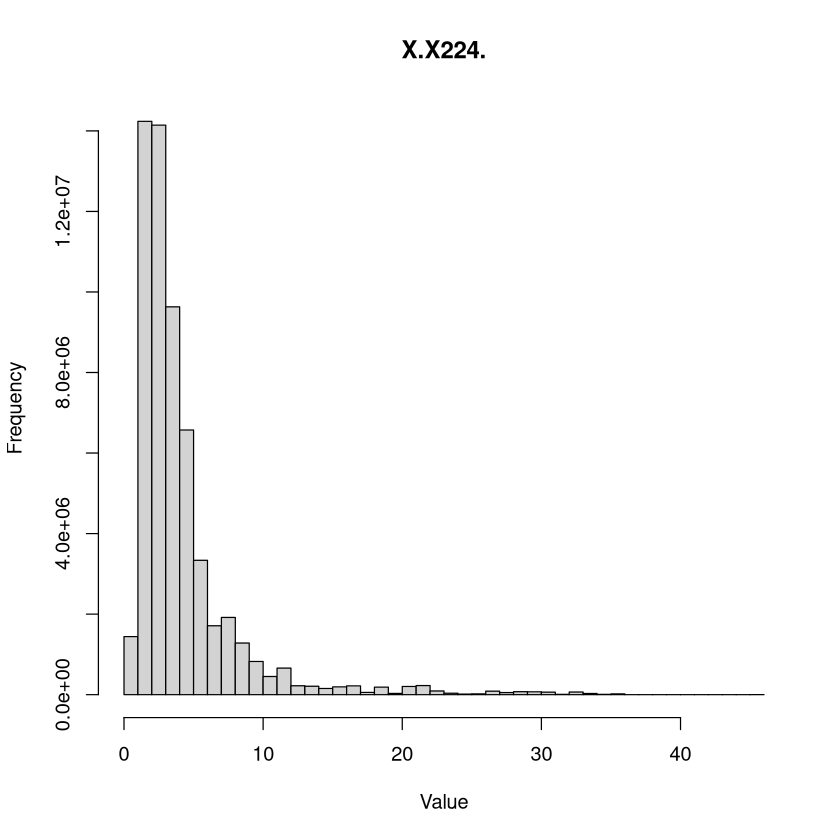

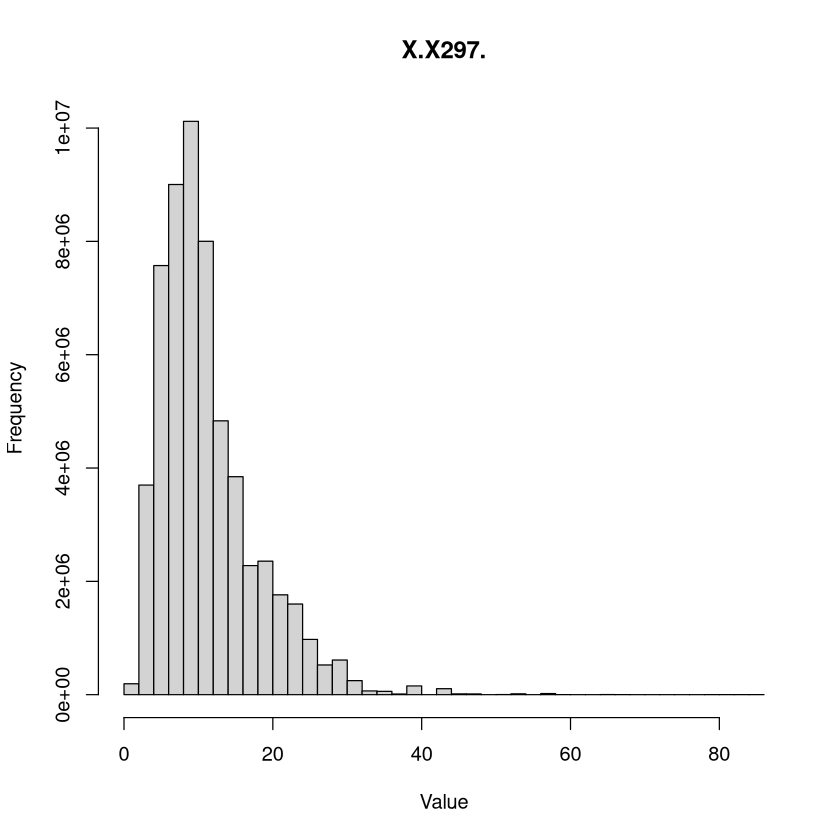

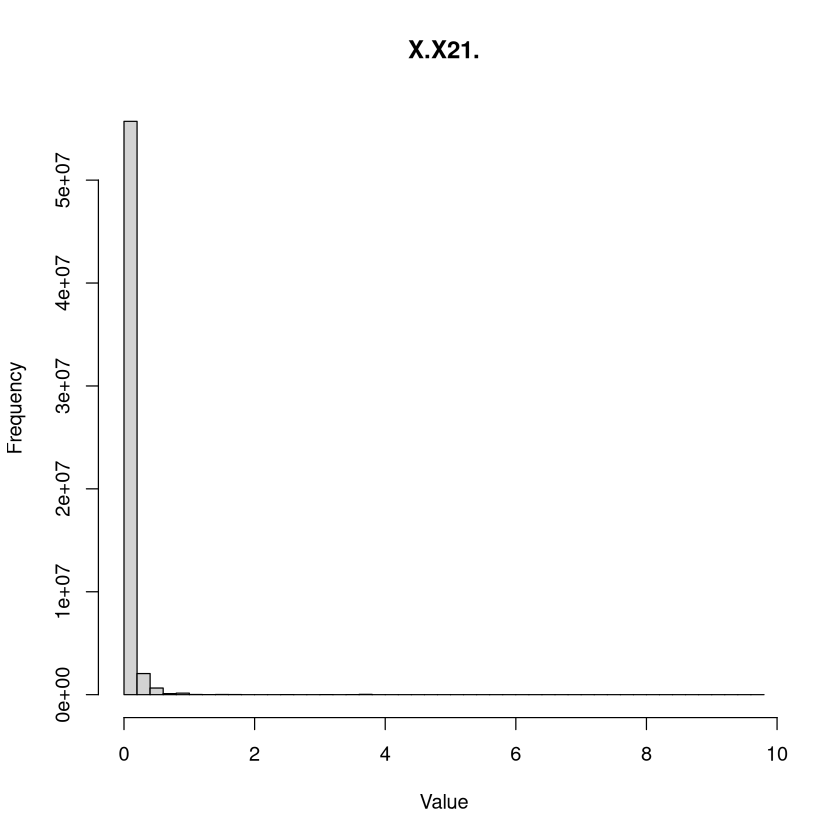

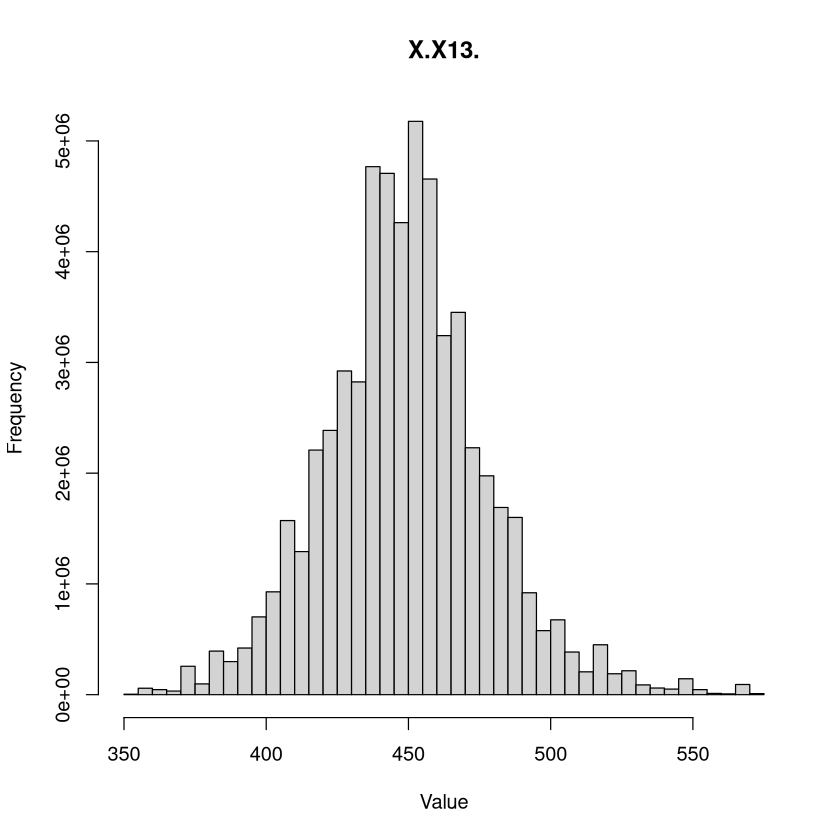

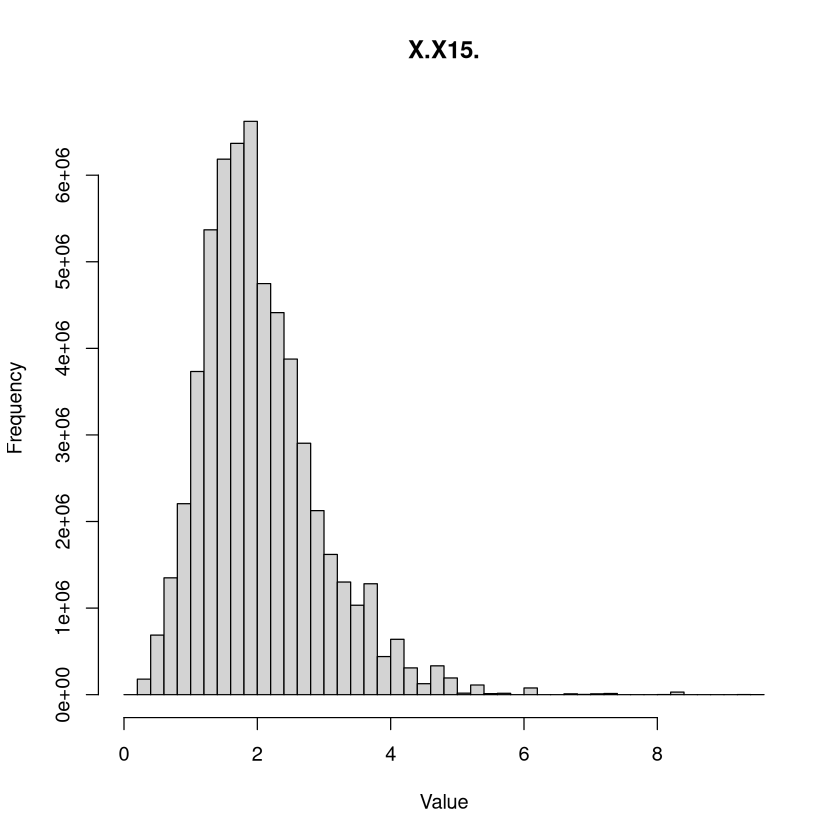

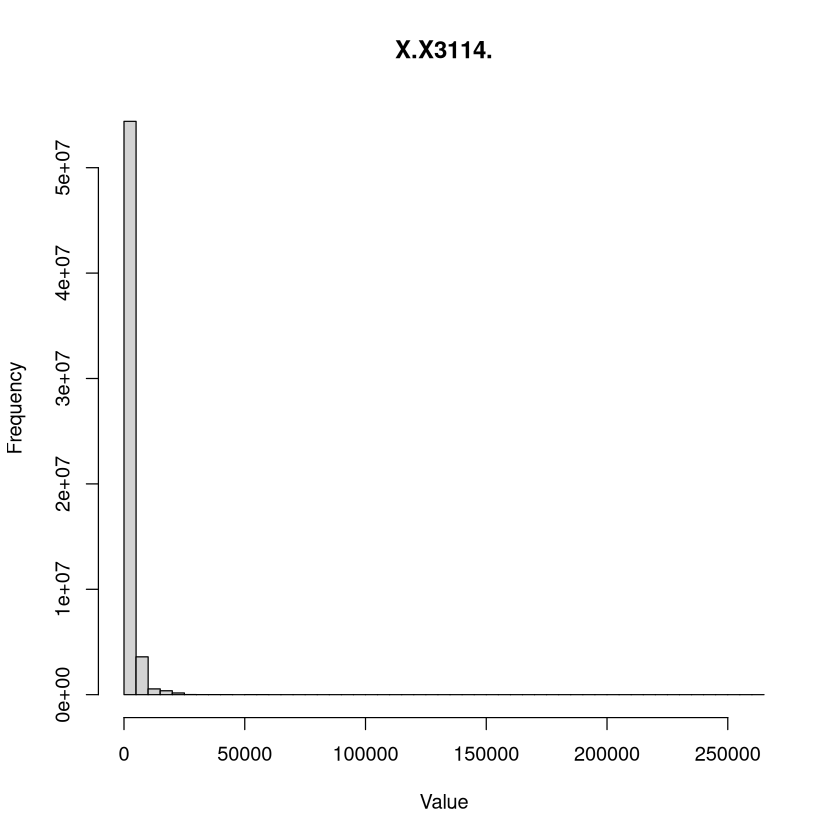

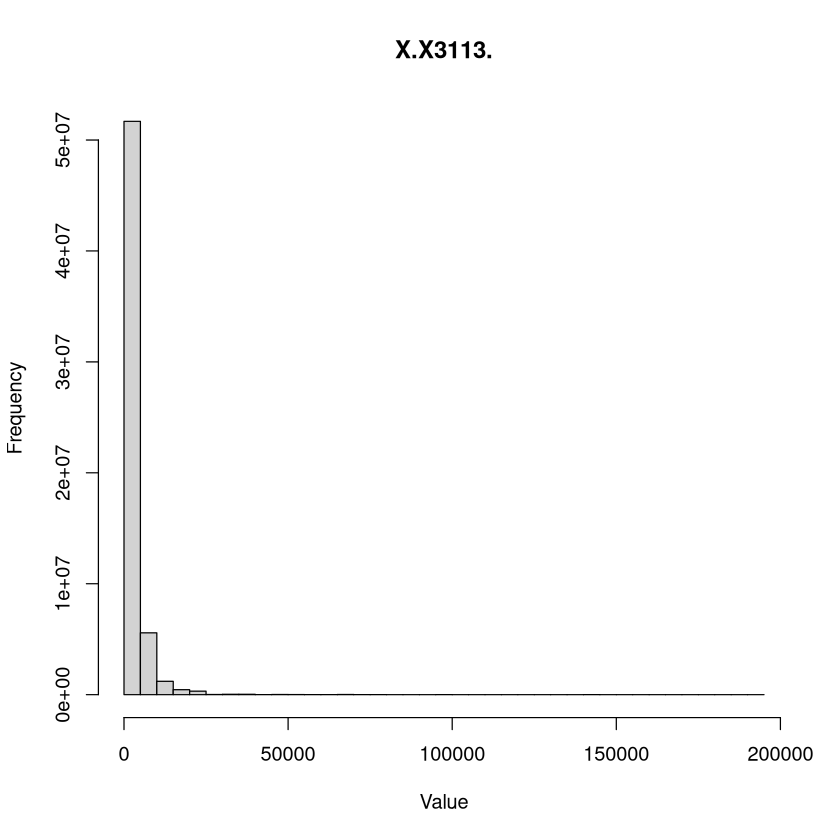

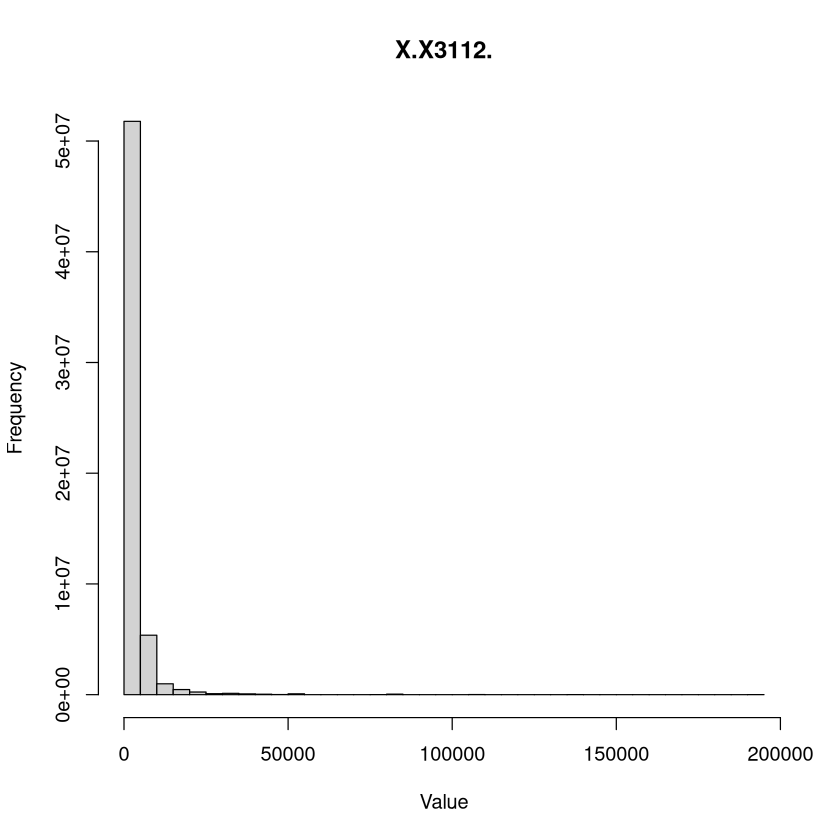

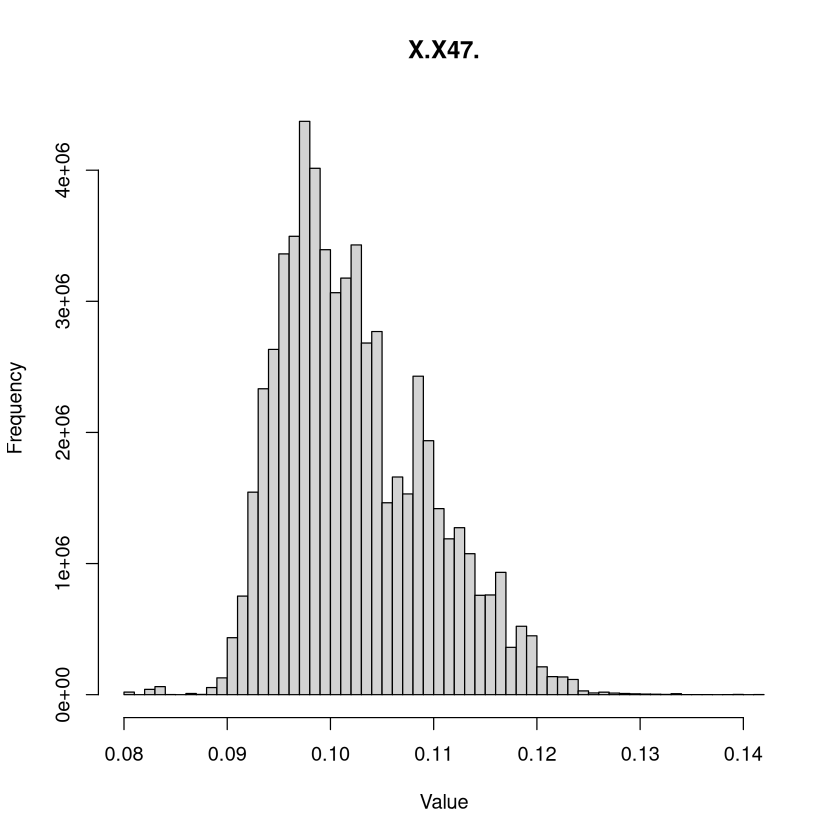

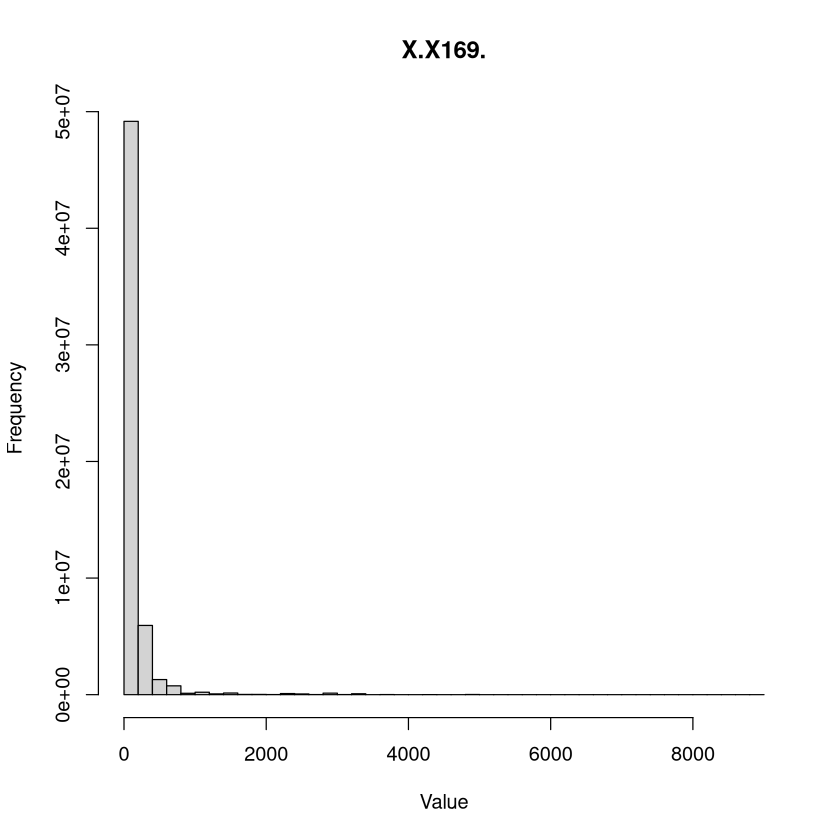

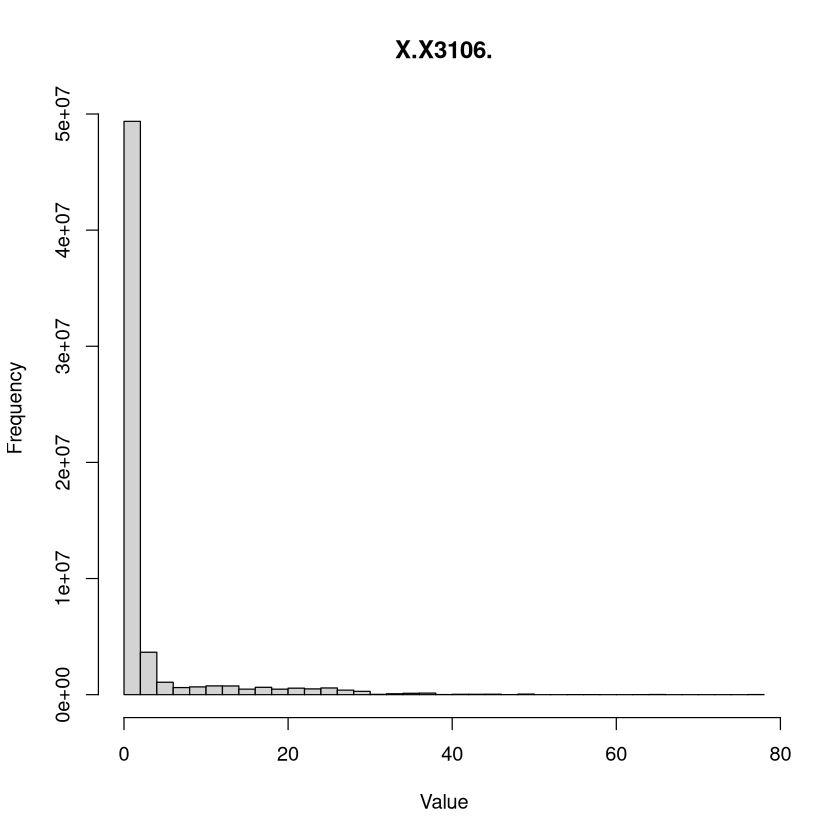

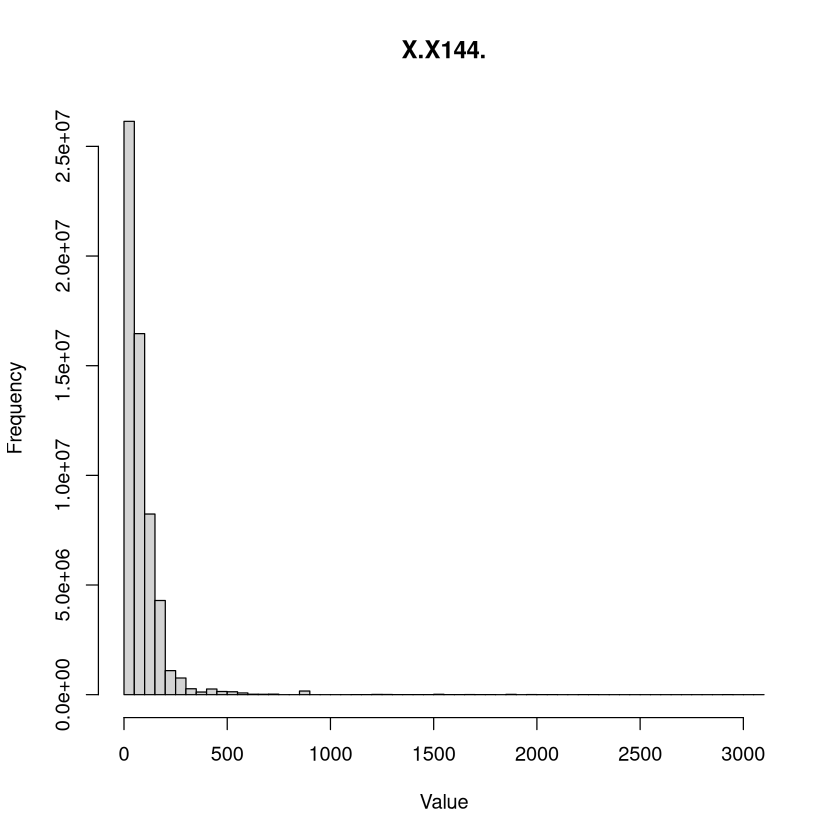

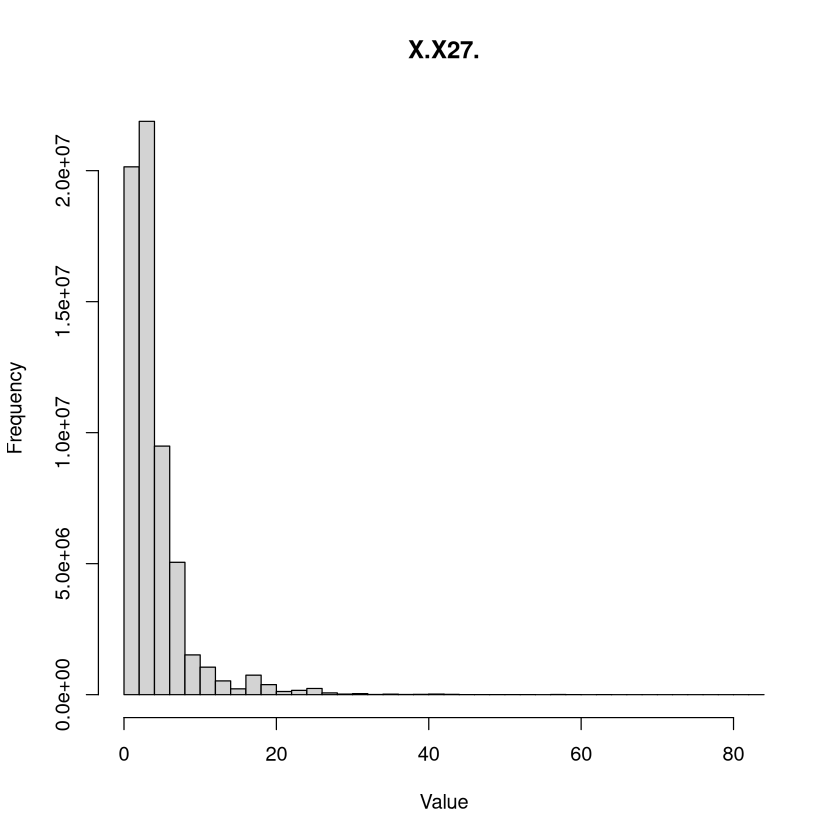

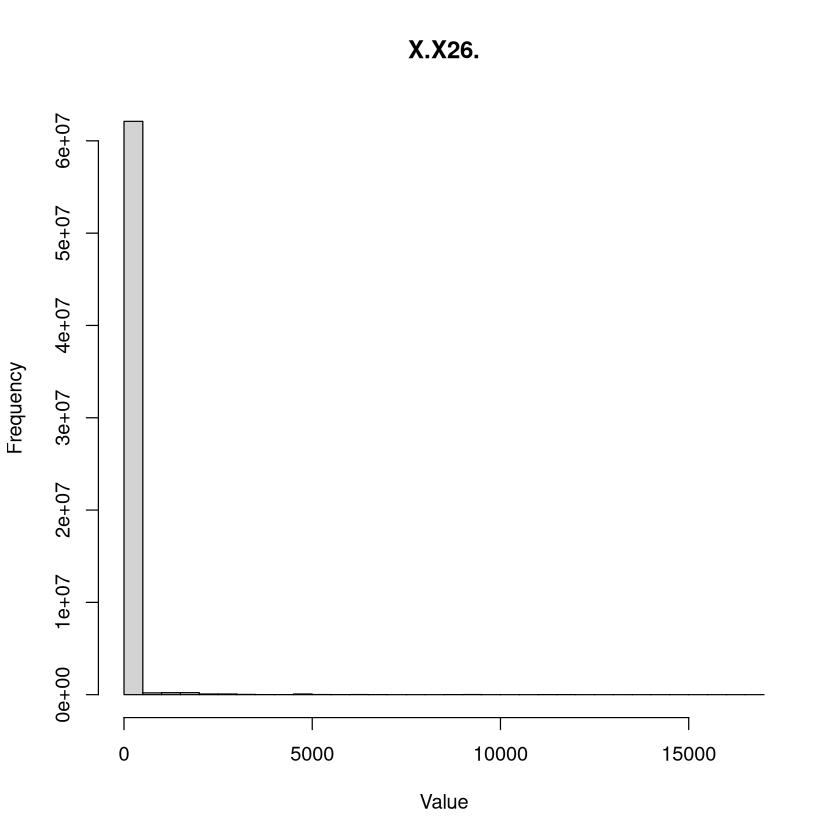

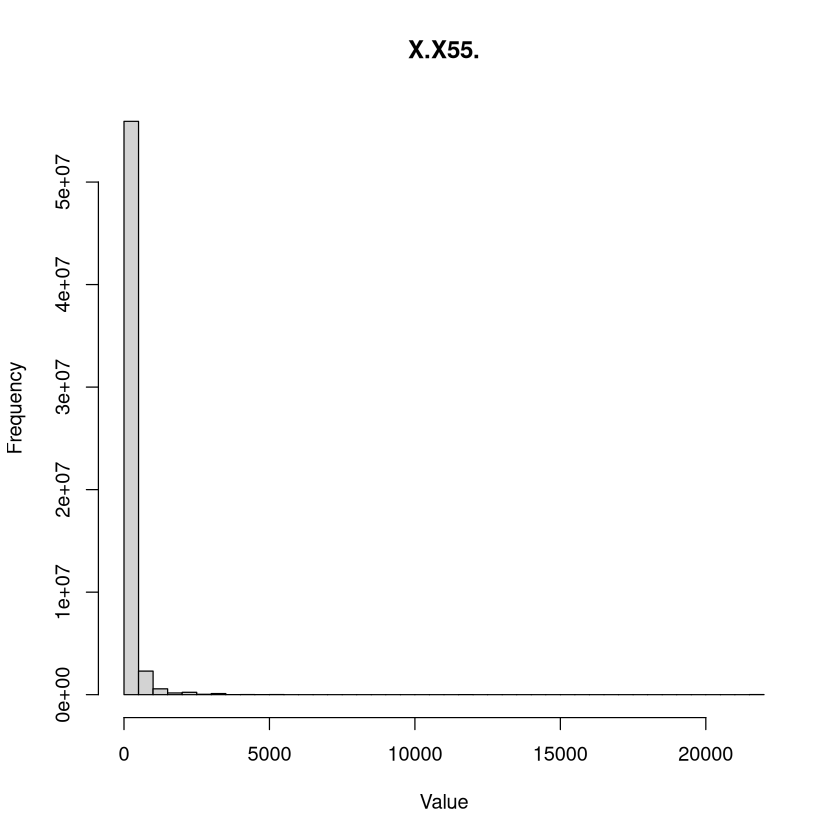

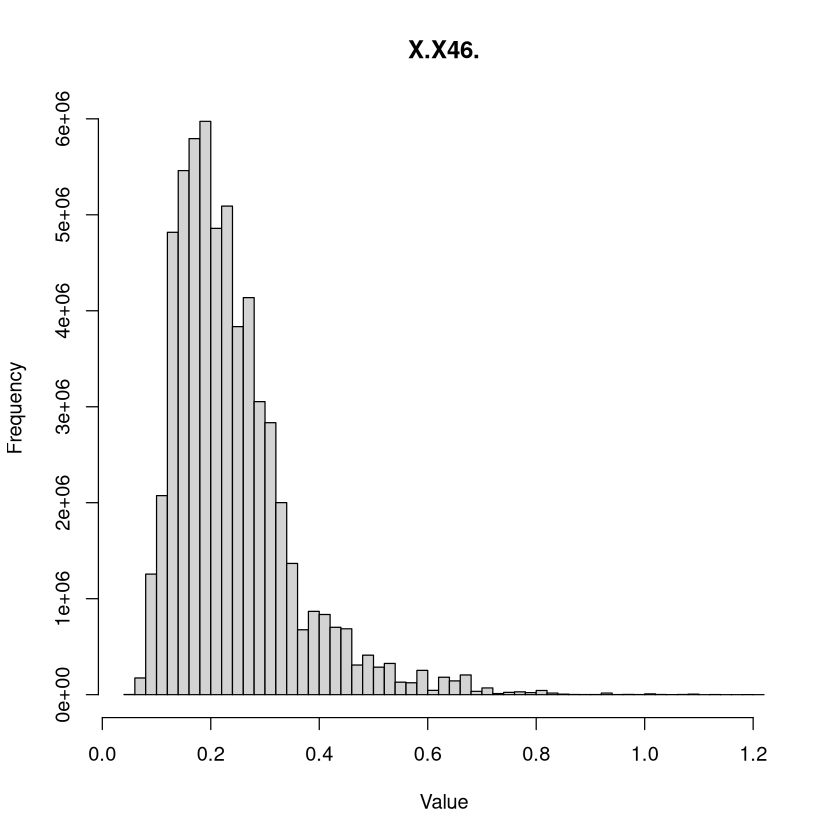

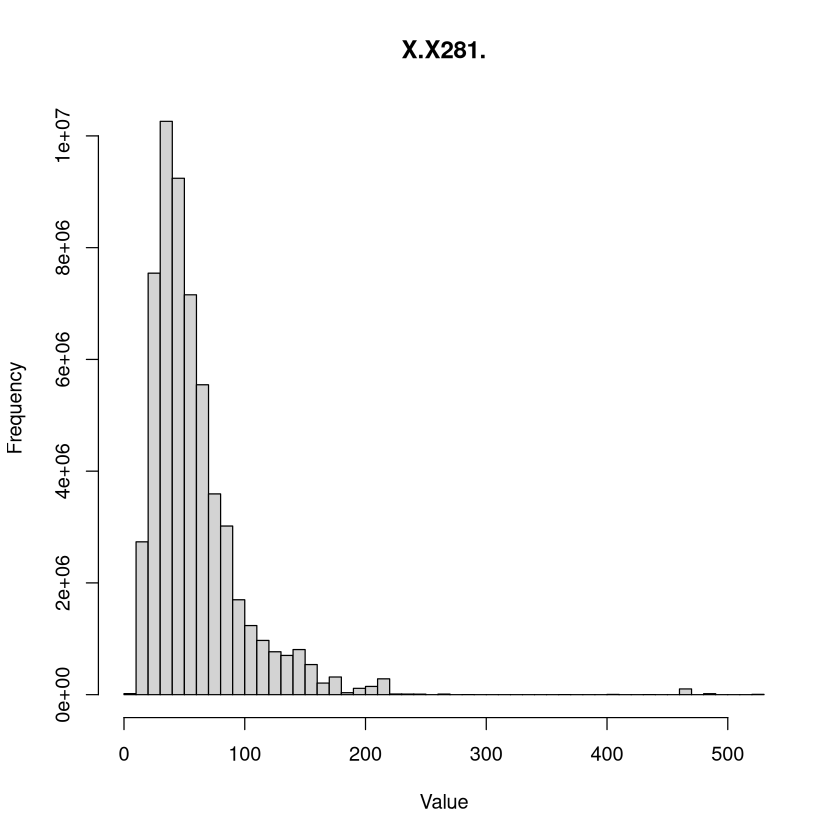

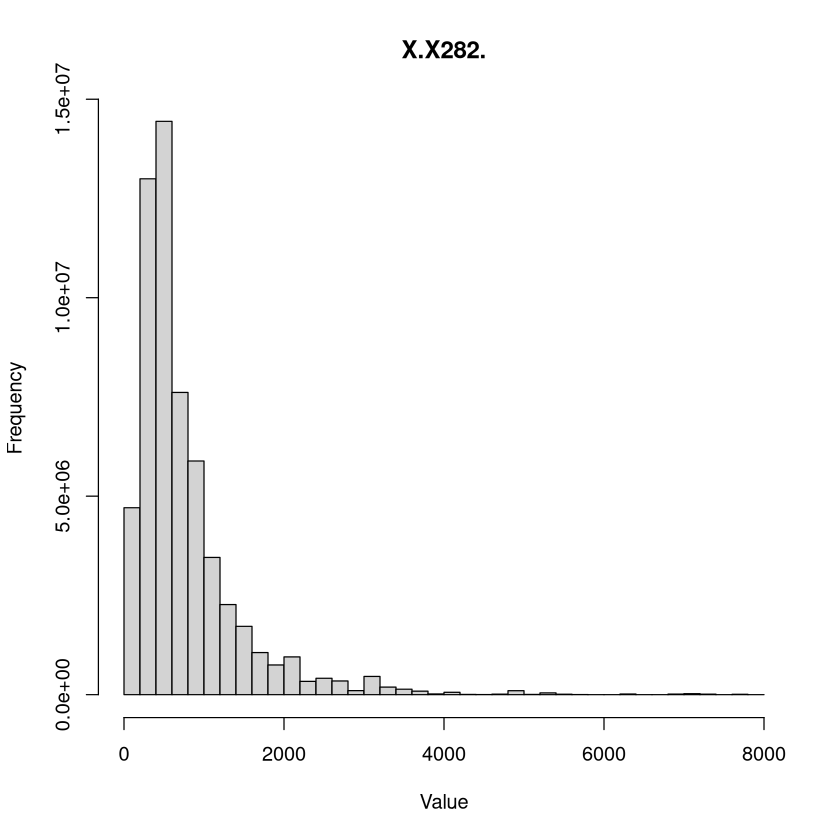

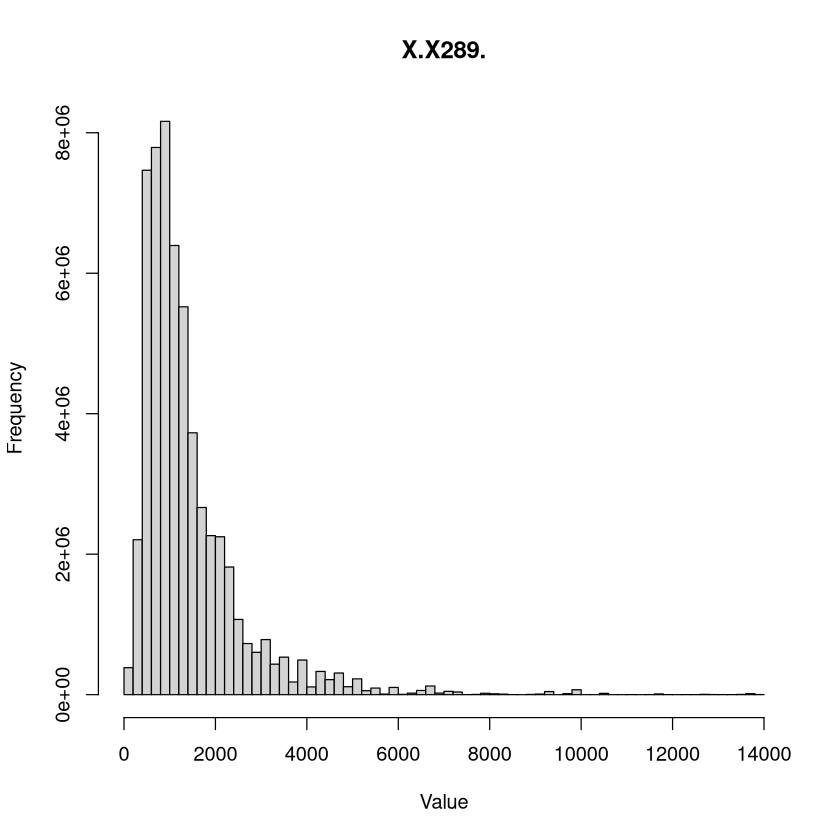

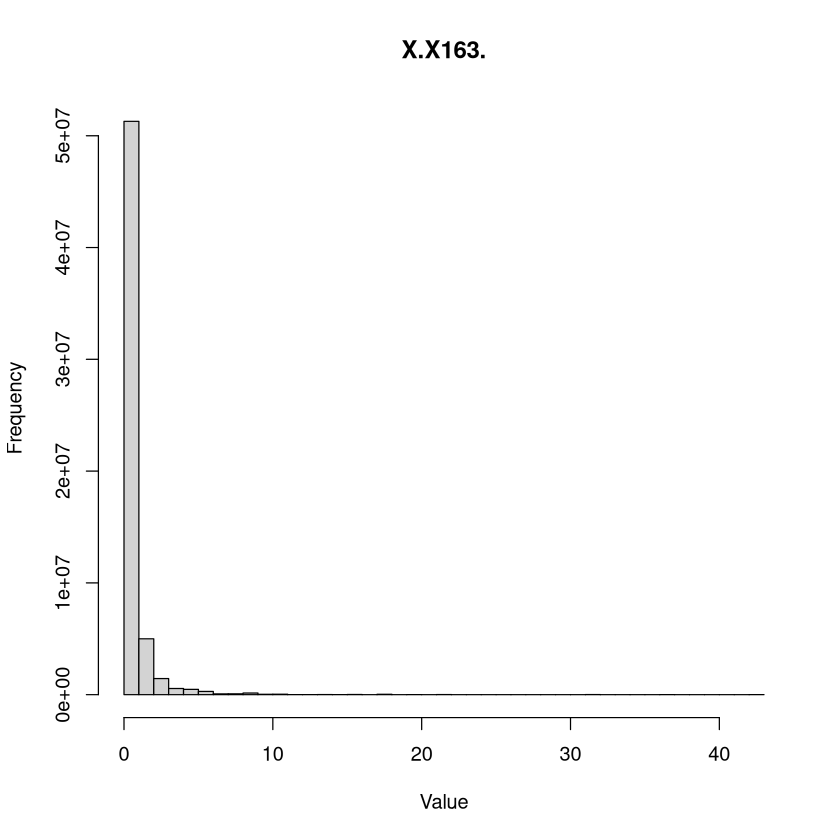

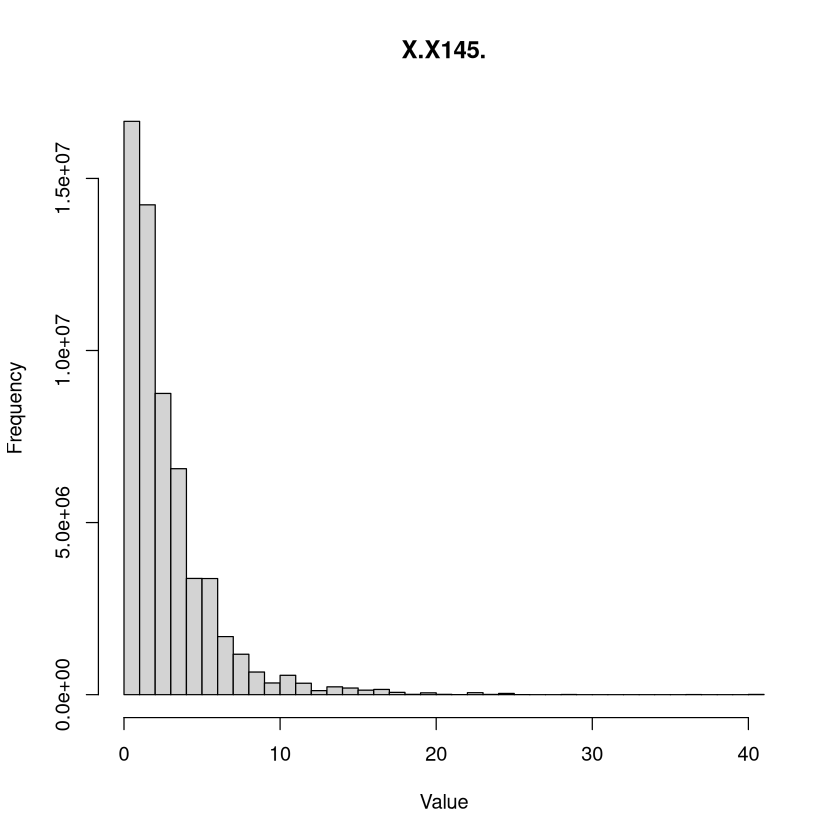

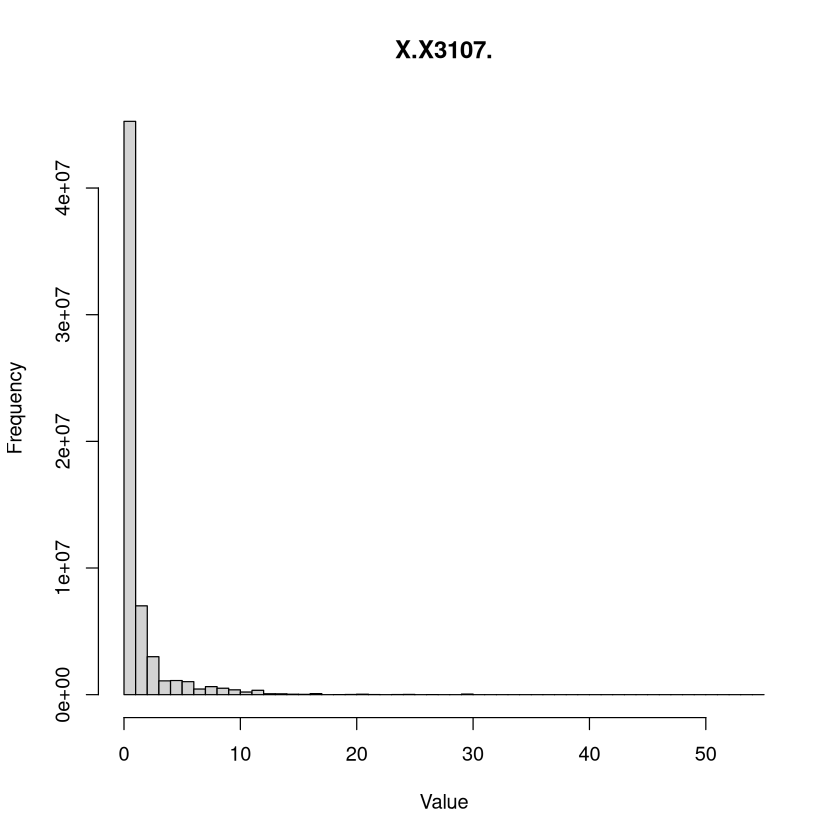

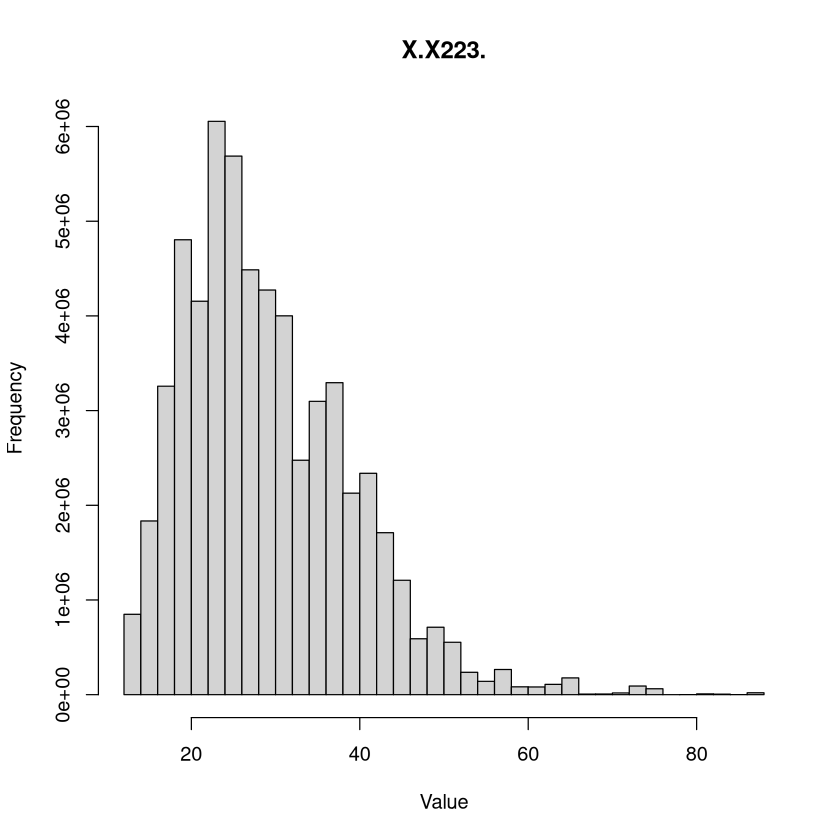

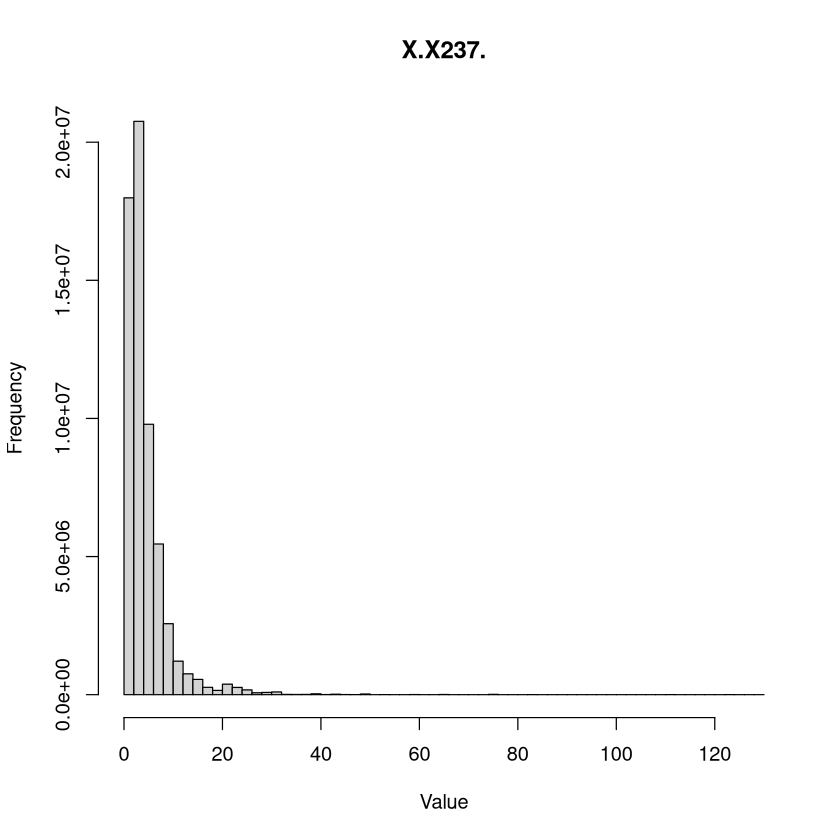

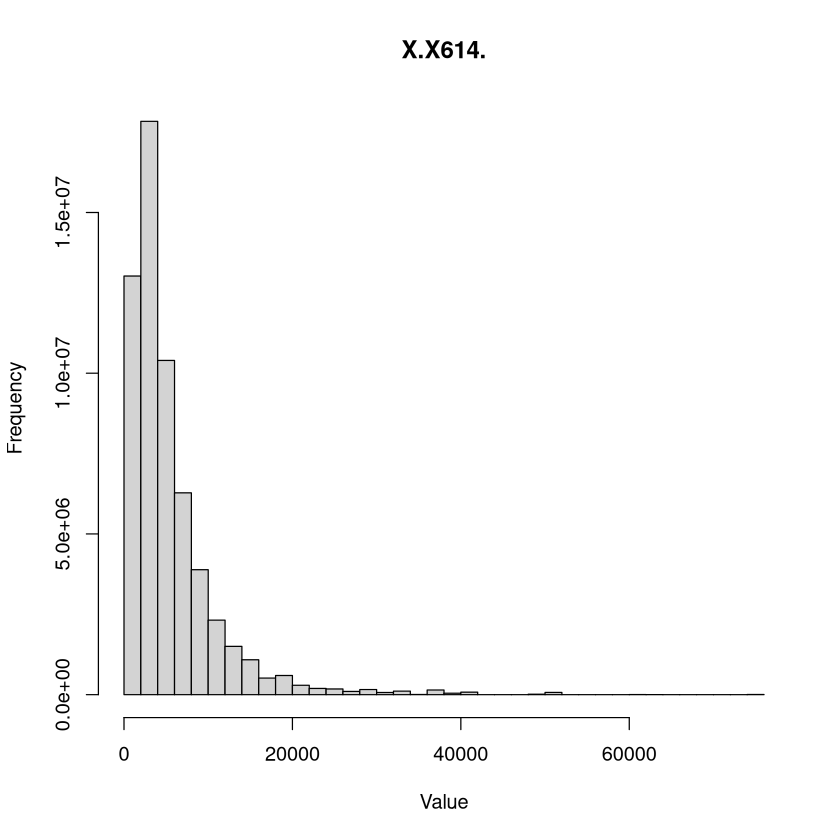

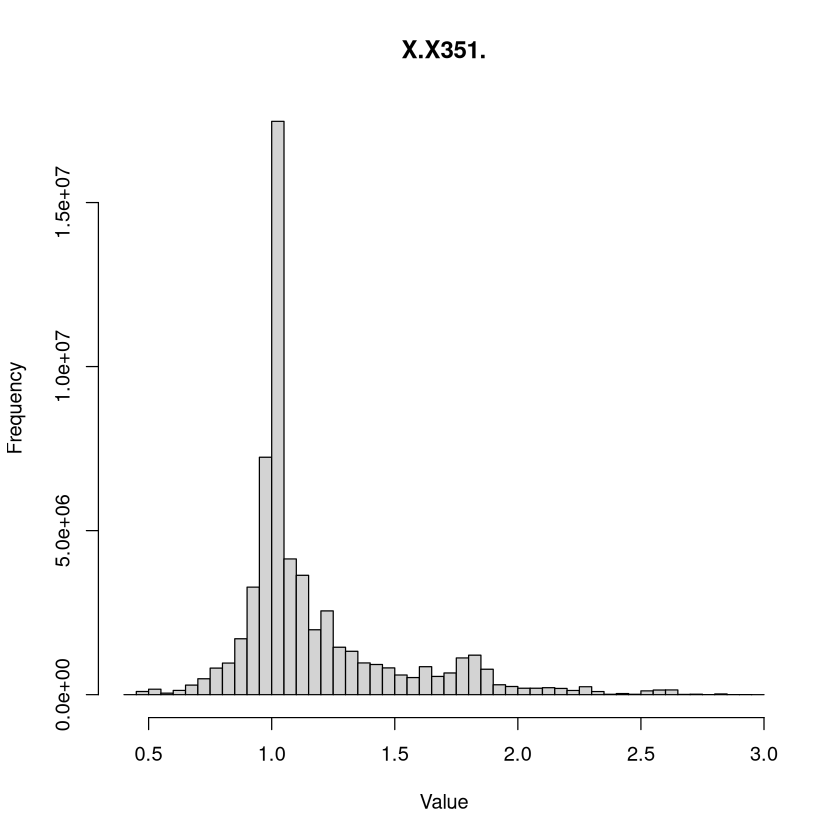

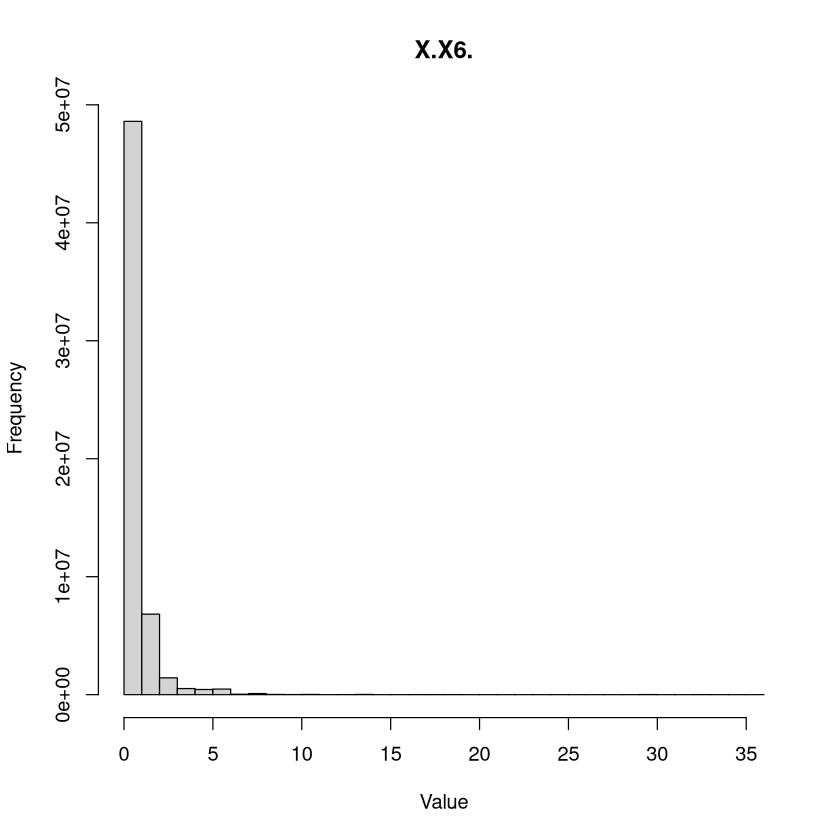

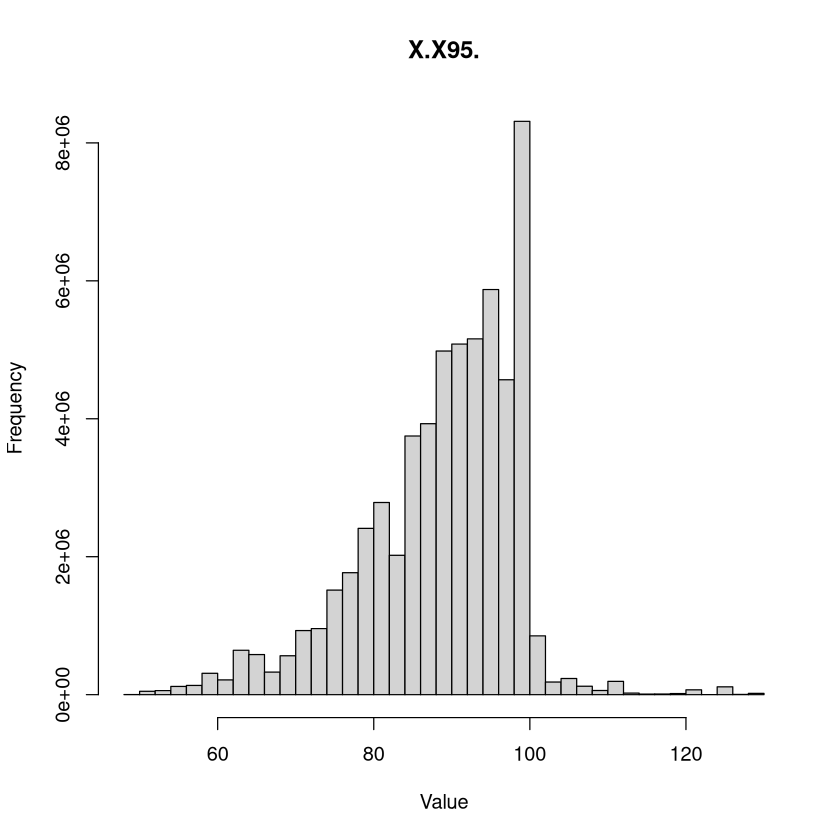

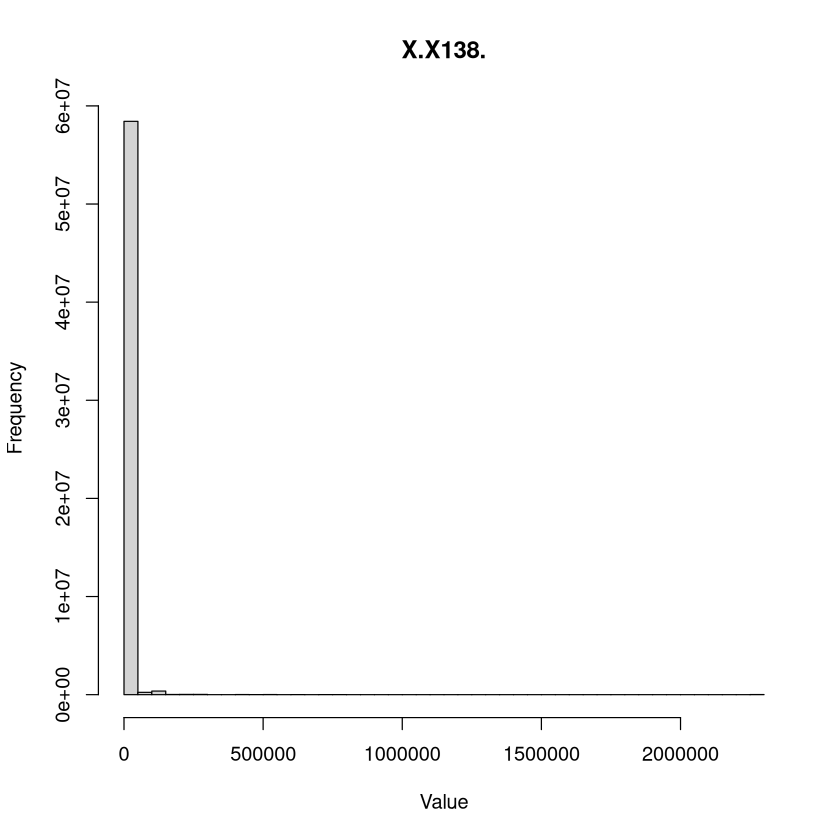

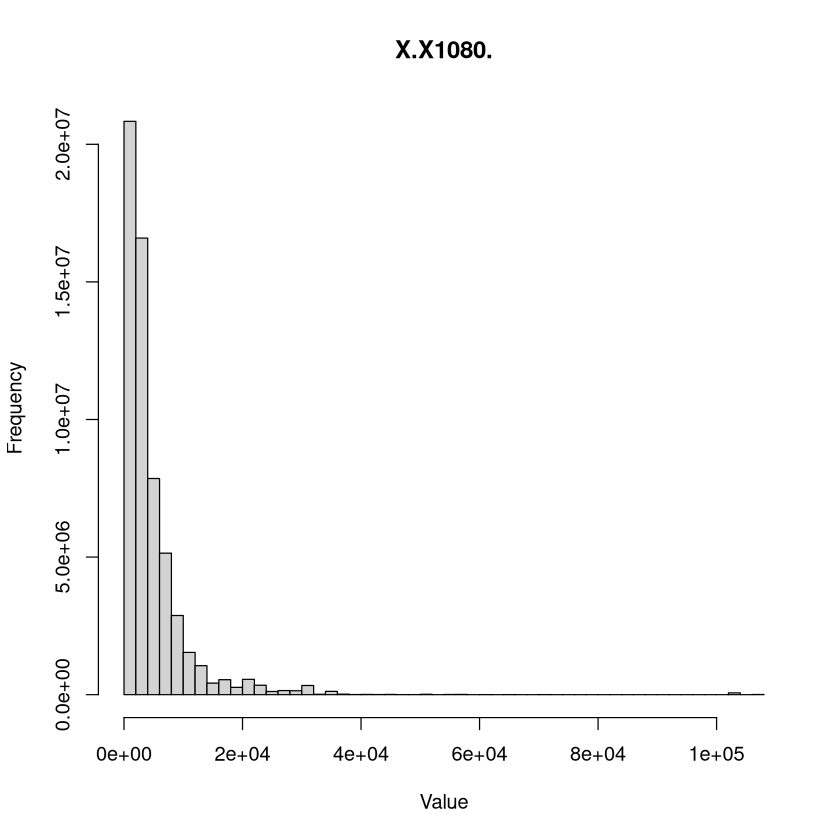

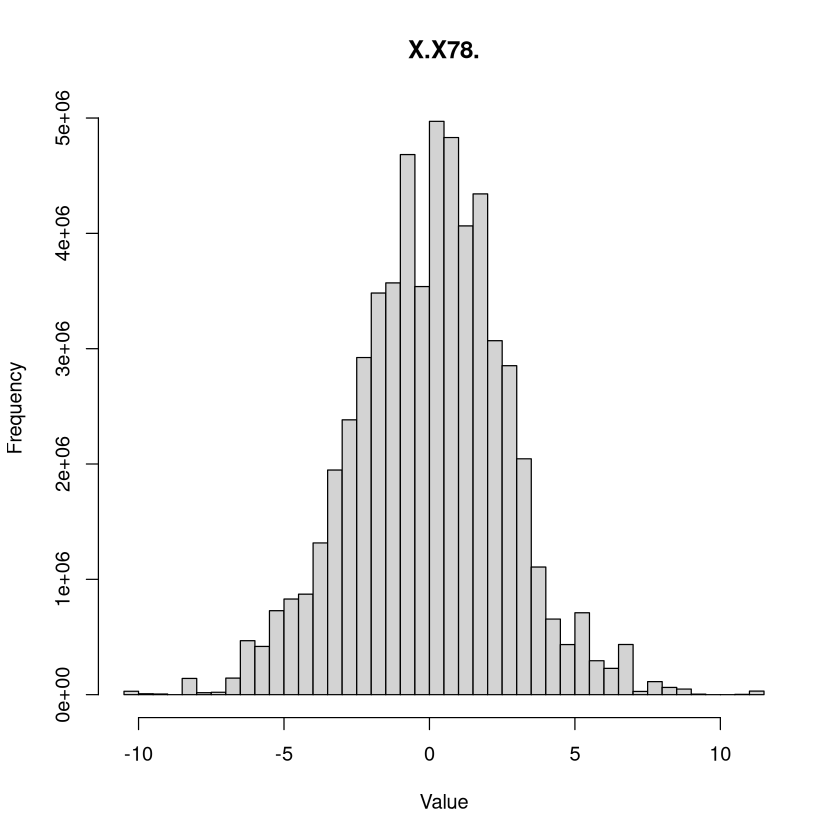

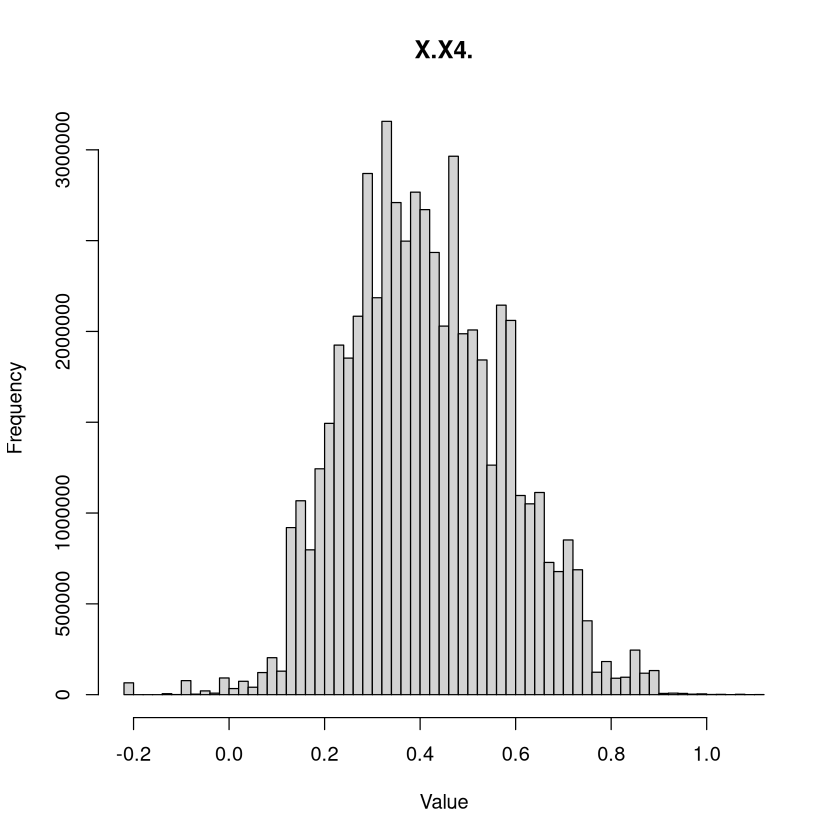

In [12]:
# get all columns that star with "X"
glonaf_cols <- grep("^X\\.", names(gbif_try_glonaf), value = TRUE)

# visualize distrubution historgramm for each glonaf_cols
for (col in glonaf_cols) {
  hist(gbif_try_glonaf[[col]], main = col, xlab = "Value", breaks = 50)
}   

In [13]:
# log10 transform all glonaf columns, except for columns X.X4., 13, 14, 15, 47, 50, 78, 95, 146, 223, 3117, 3120
glonaf_cols_to_transform <- setdiff(glonaf_cols, c("X.X4.", "X.X13.", "X.X14.", "X.X15.", "X.X47.", "X.X50.", "X.X78.", "X.X95.", "X.X146.", "X.X223.", "X.X3117.", "X.X3120."))    
for (col in glonaf_cols_to_transform) {
  gbif_try_glonaf[[col]] <- log10(gbif_try_glonaf[[col]]) 
}

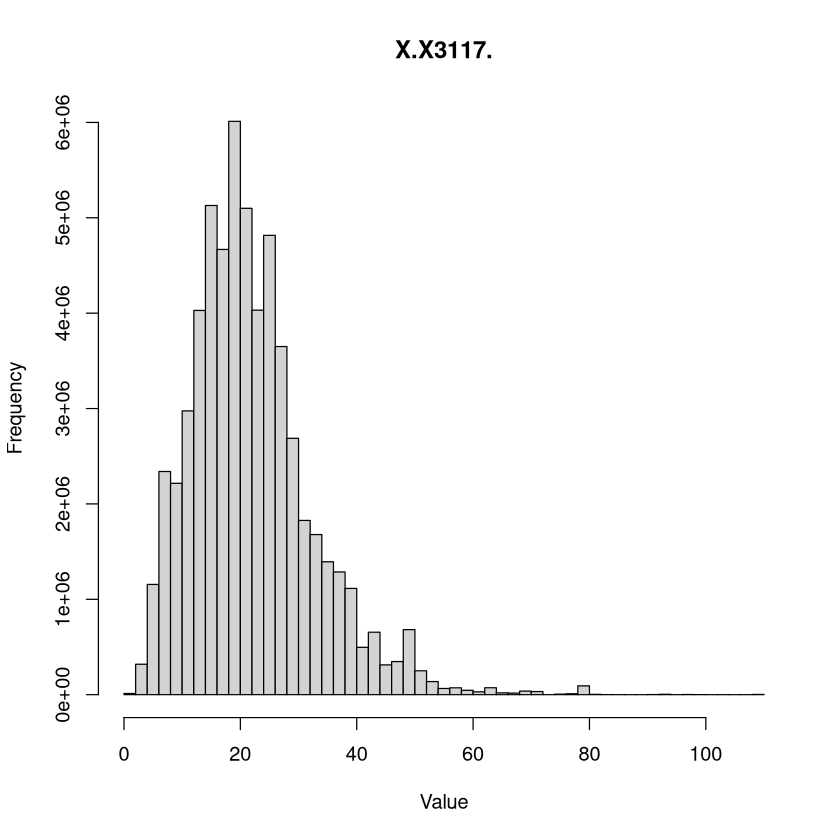

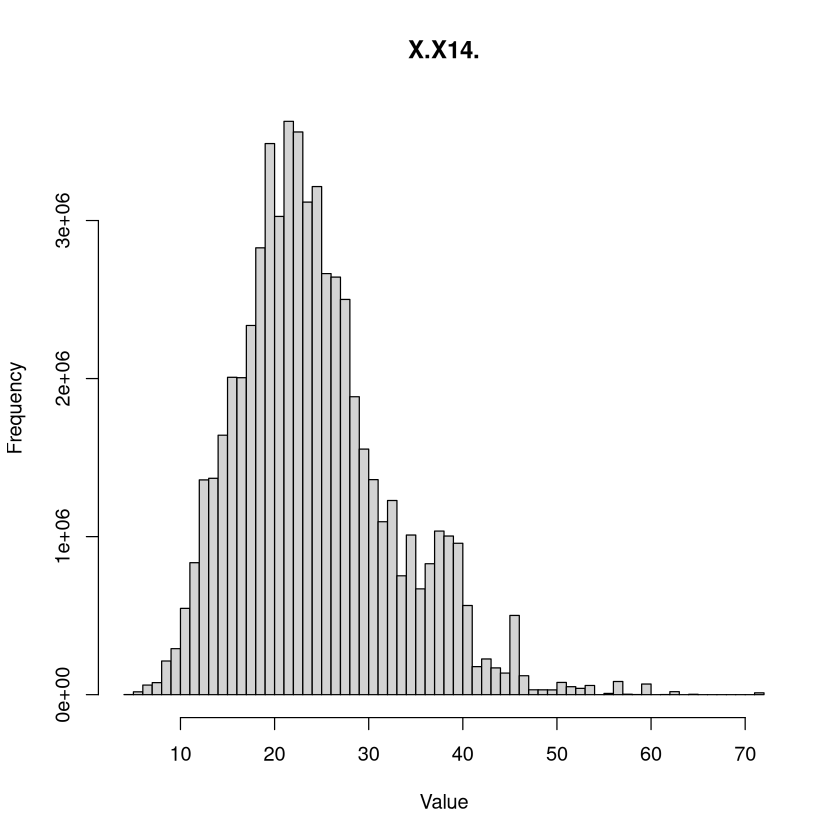

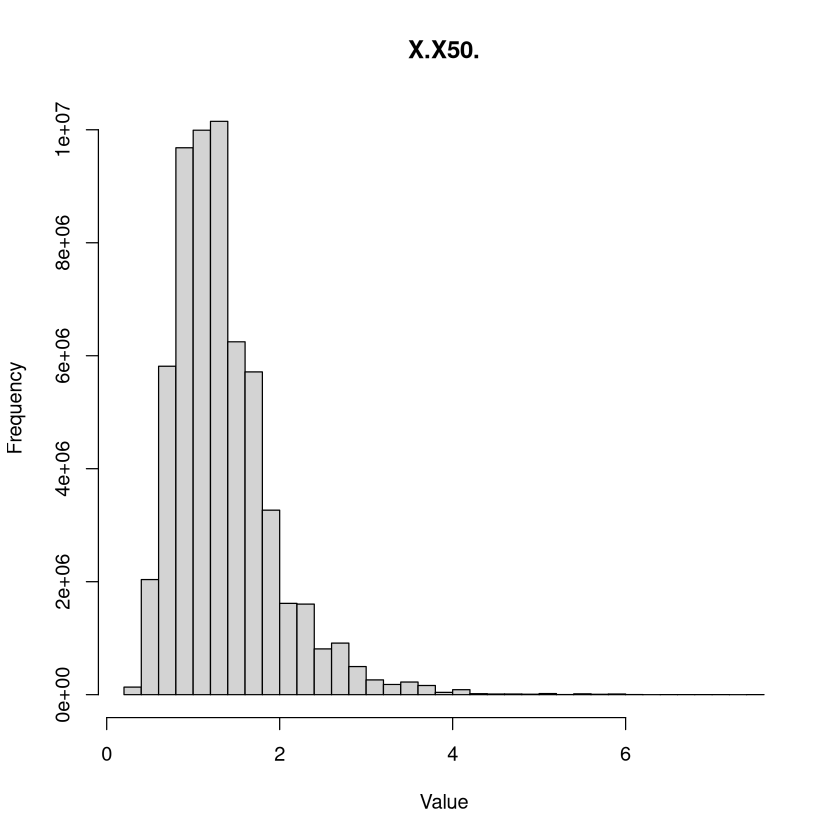

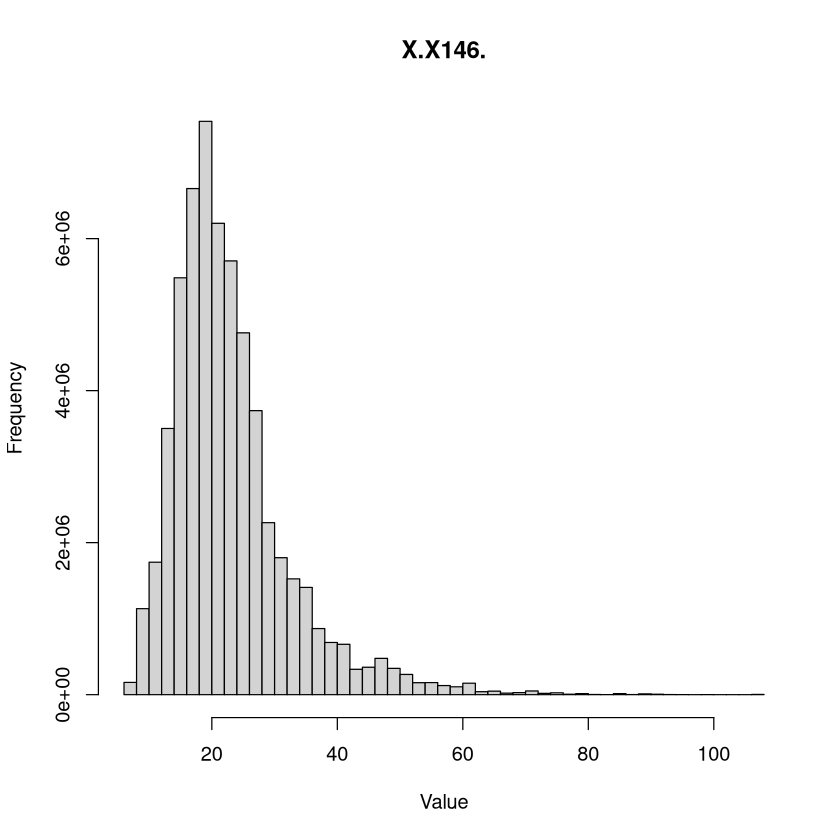

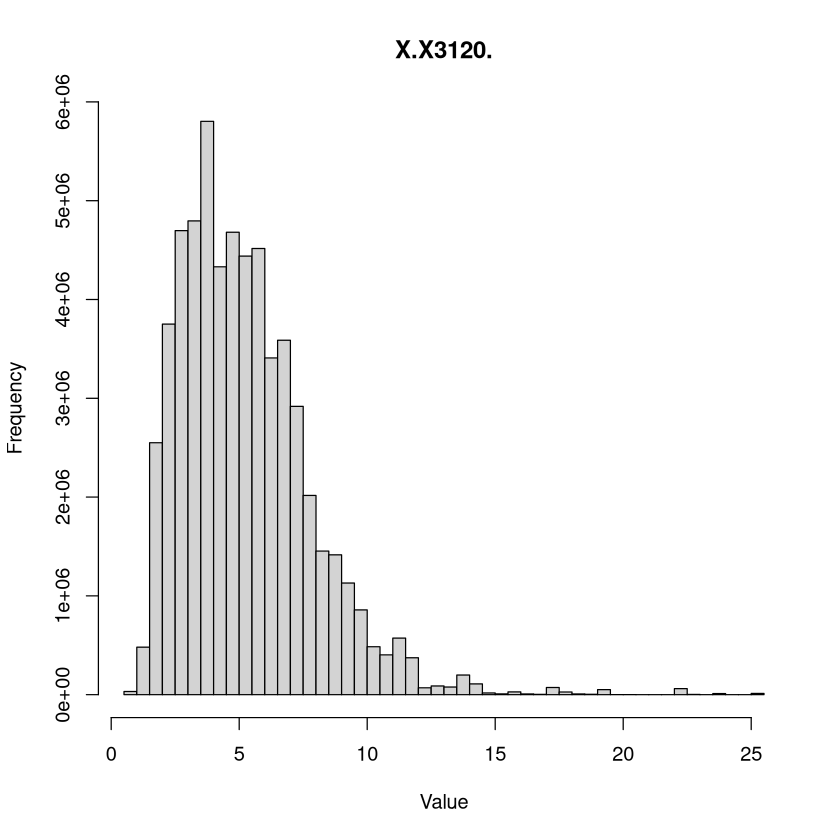

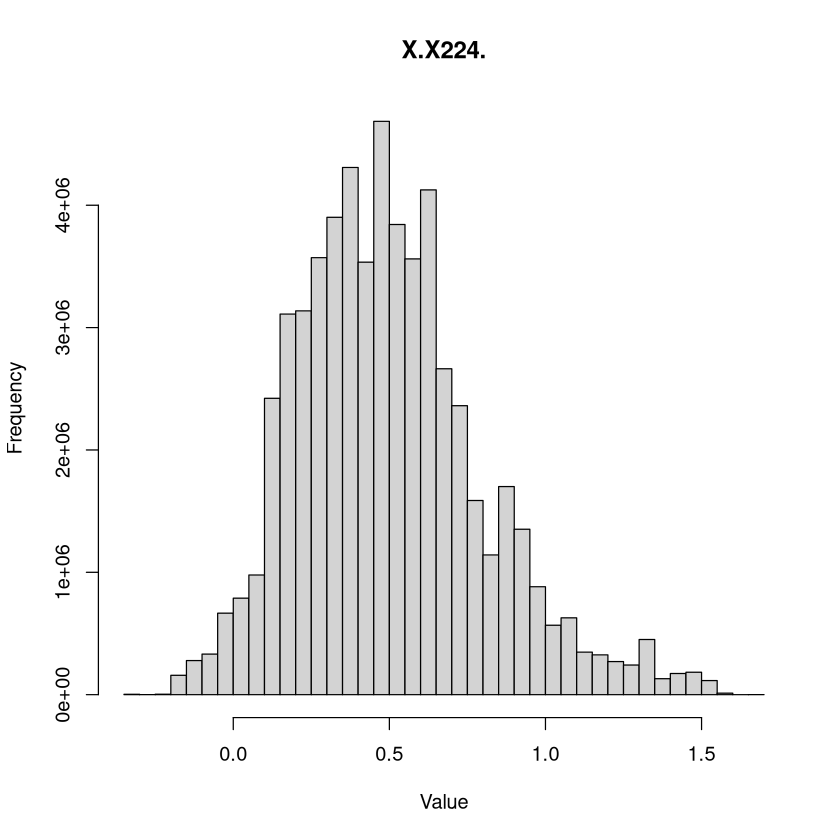

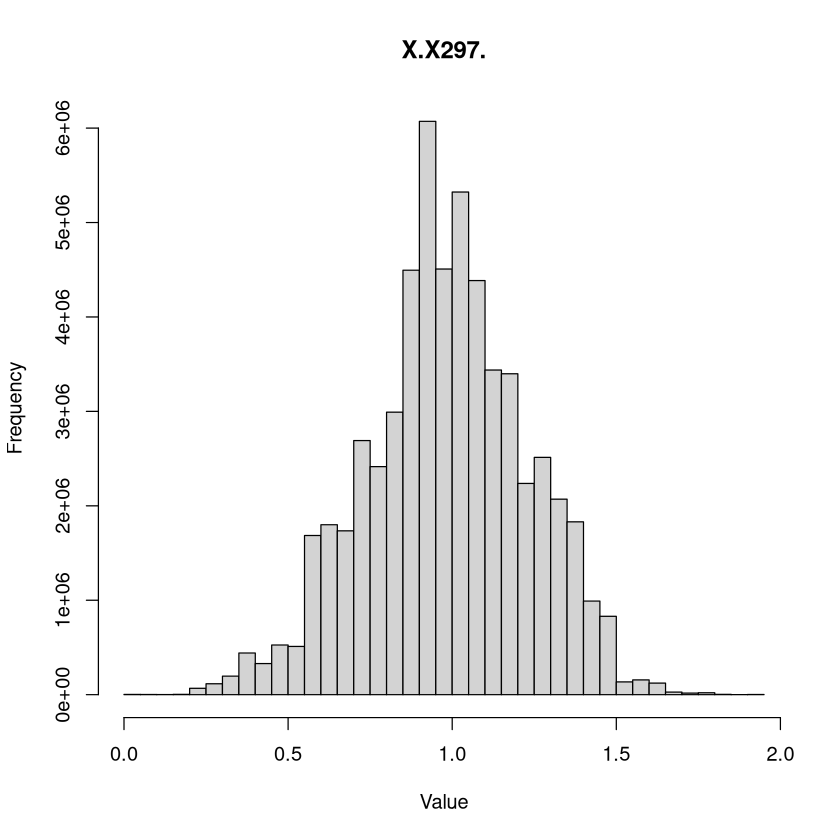

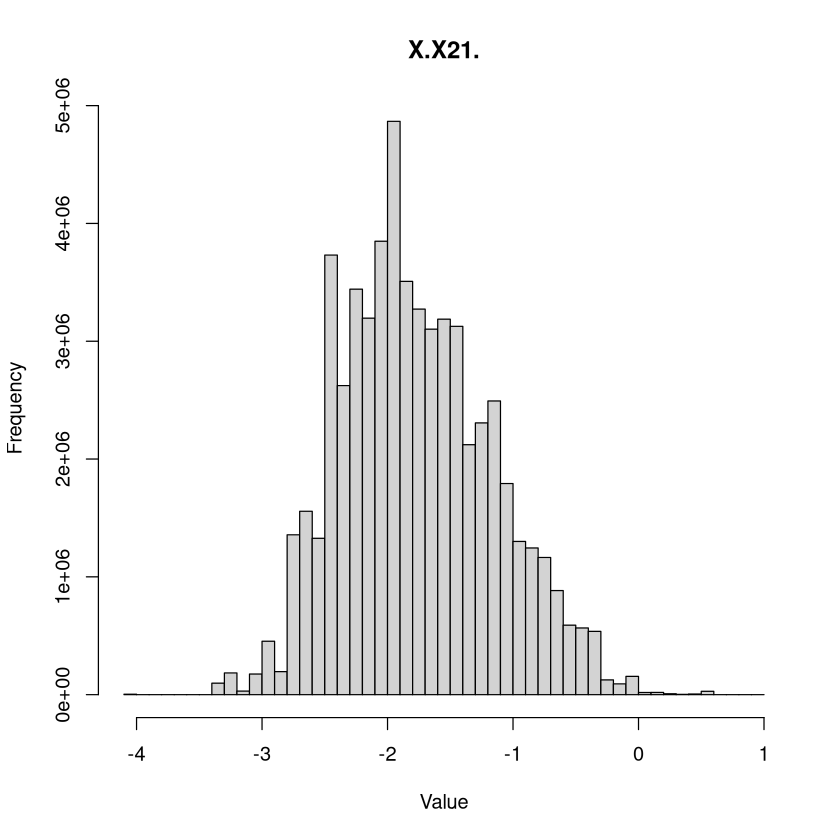

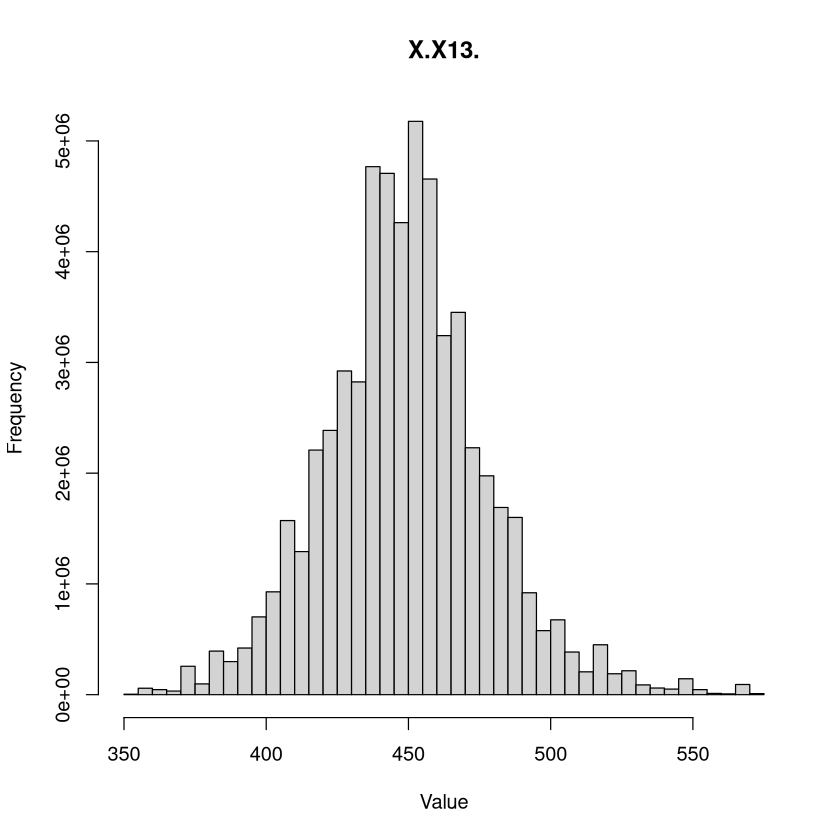

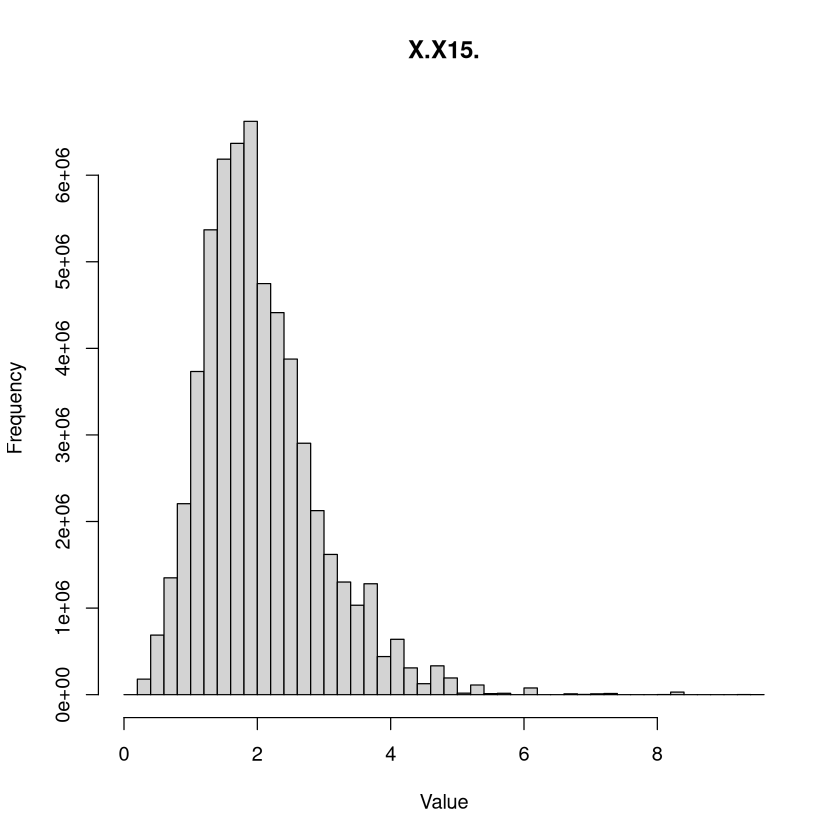

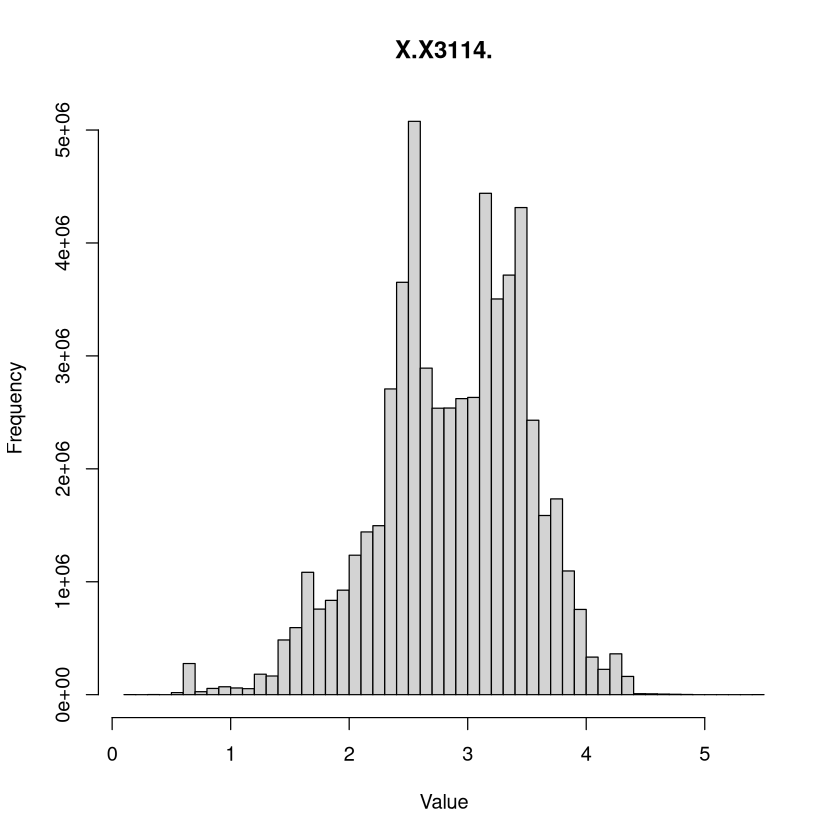

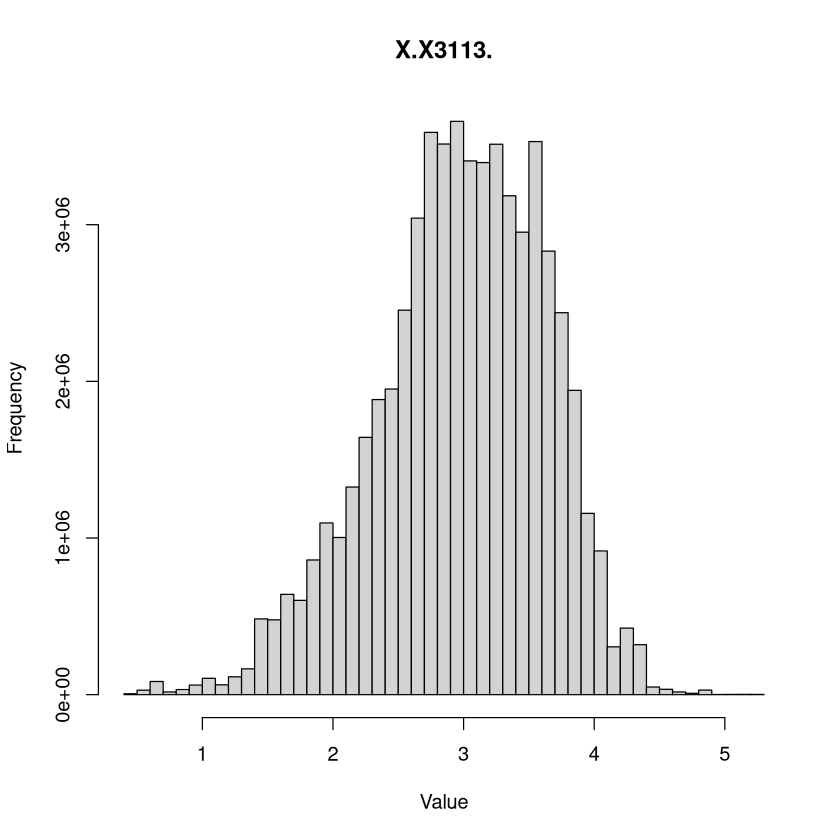

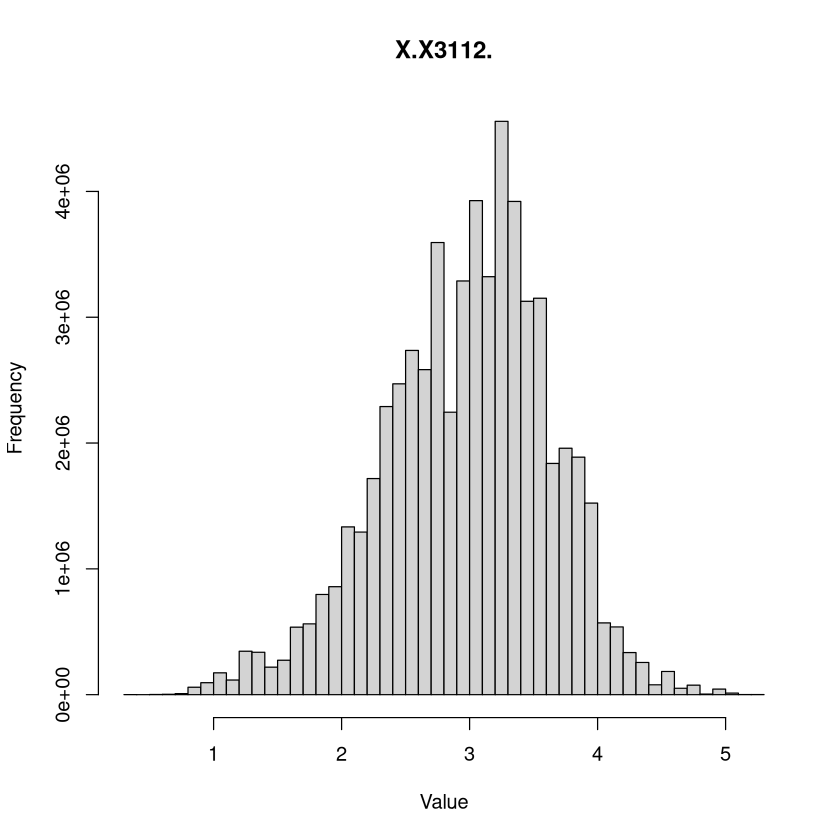

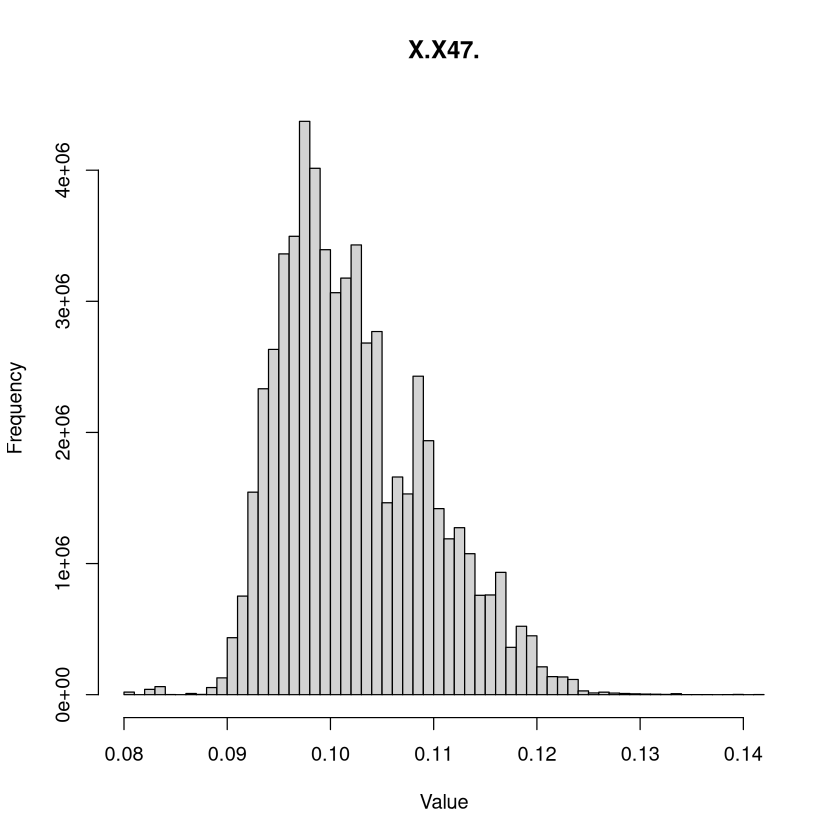

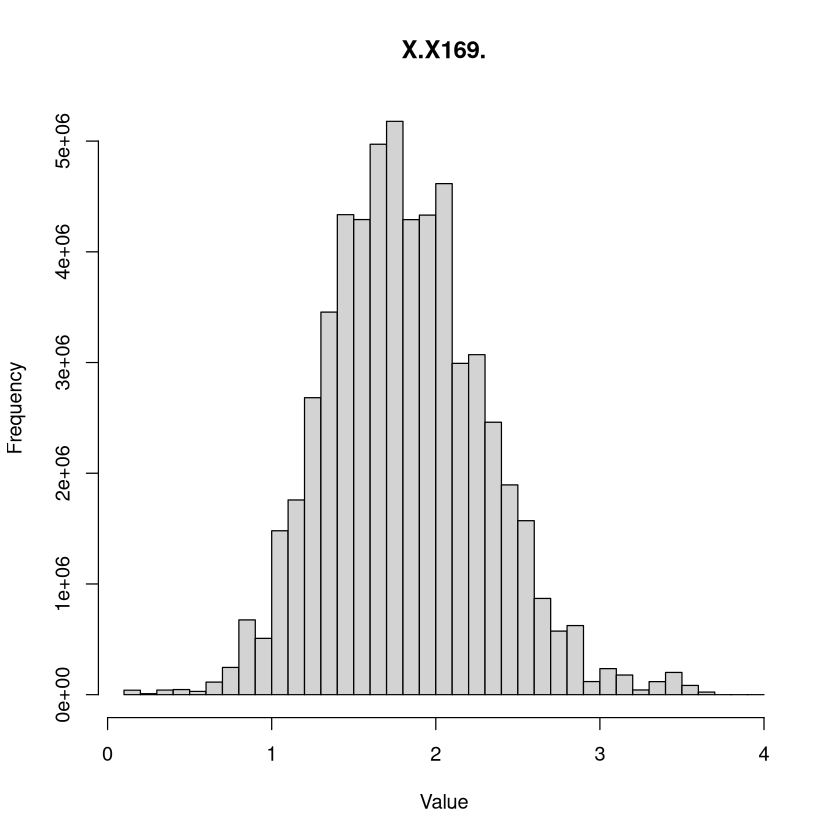

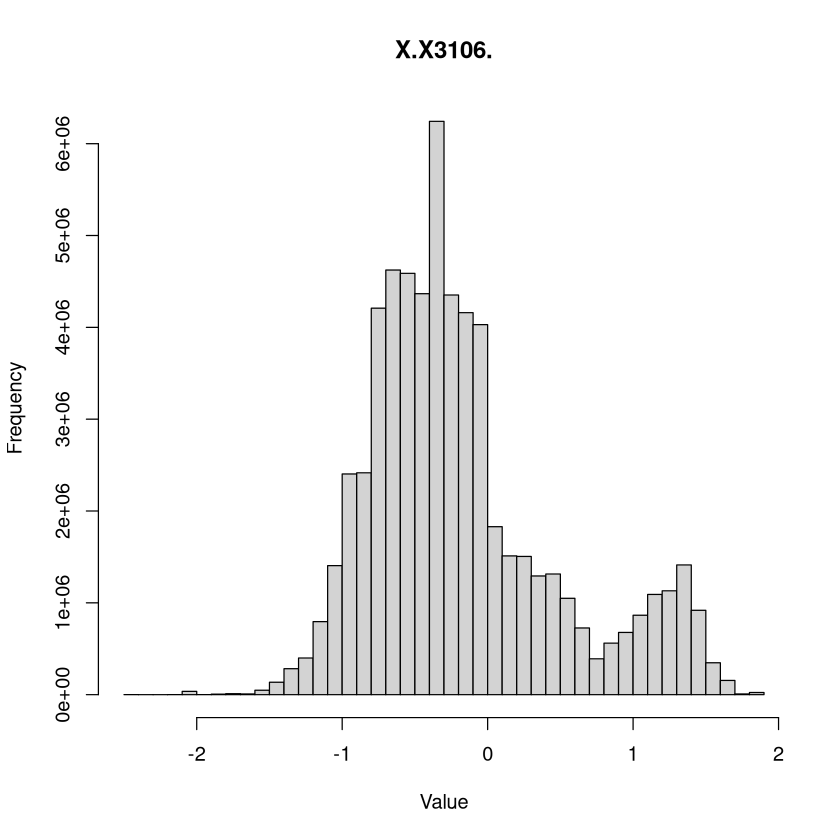

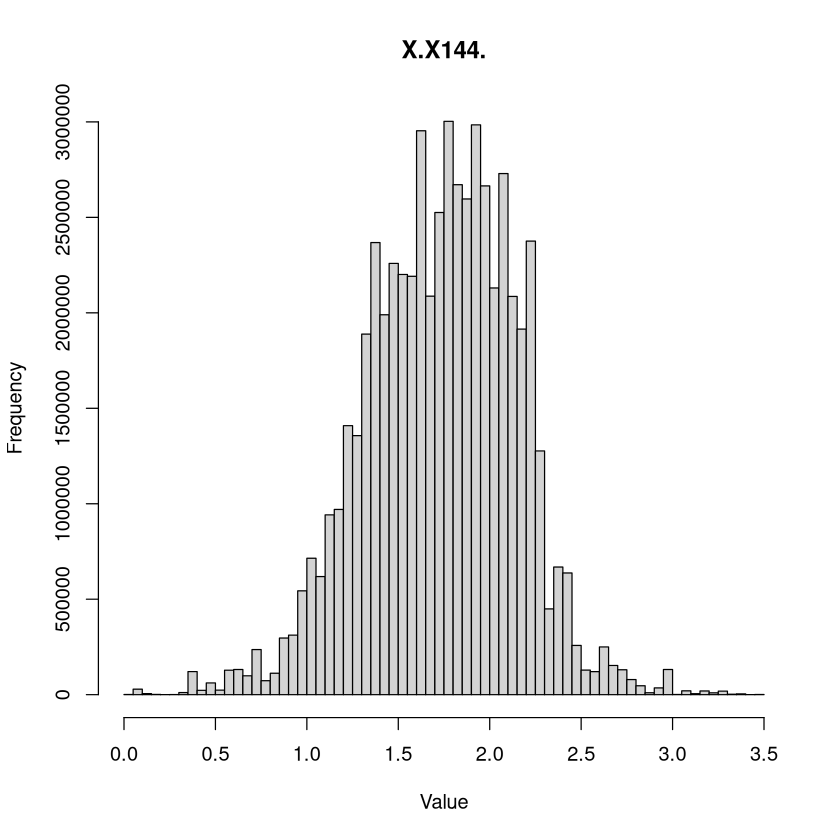

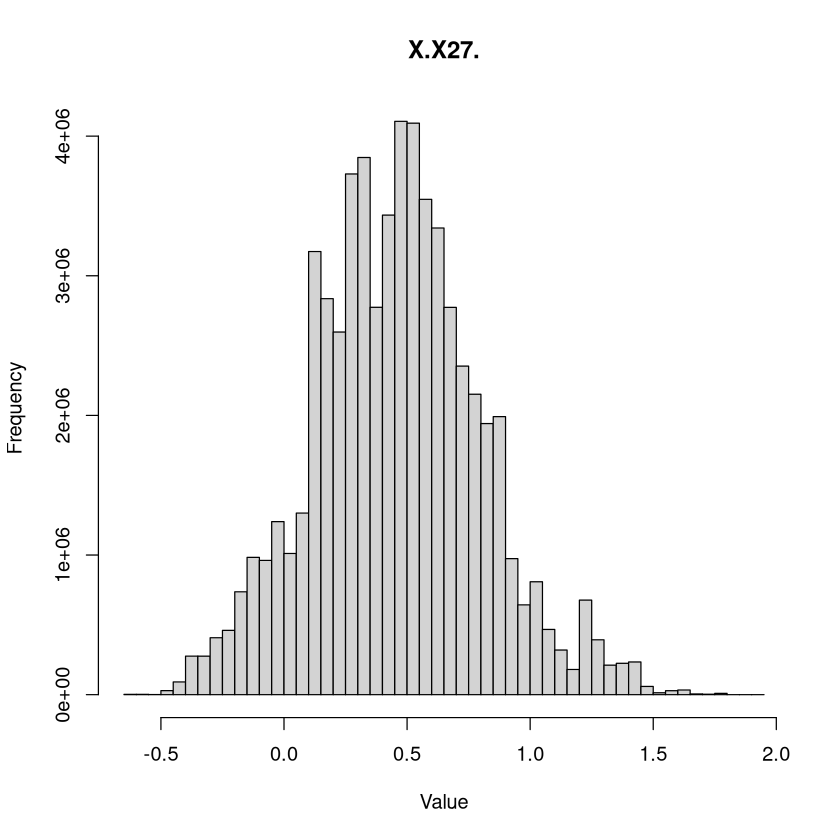

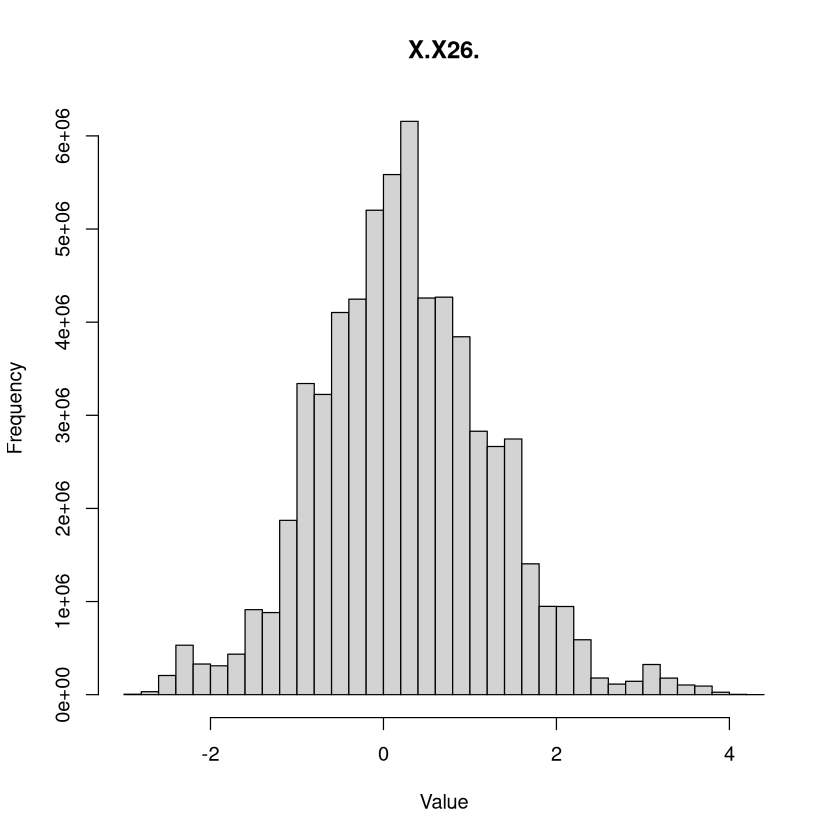

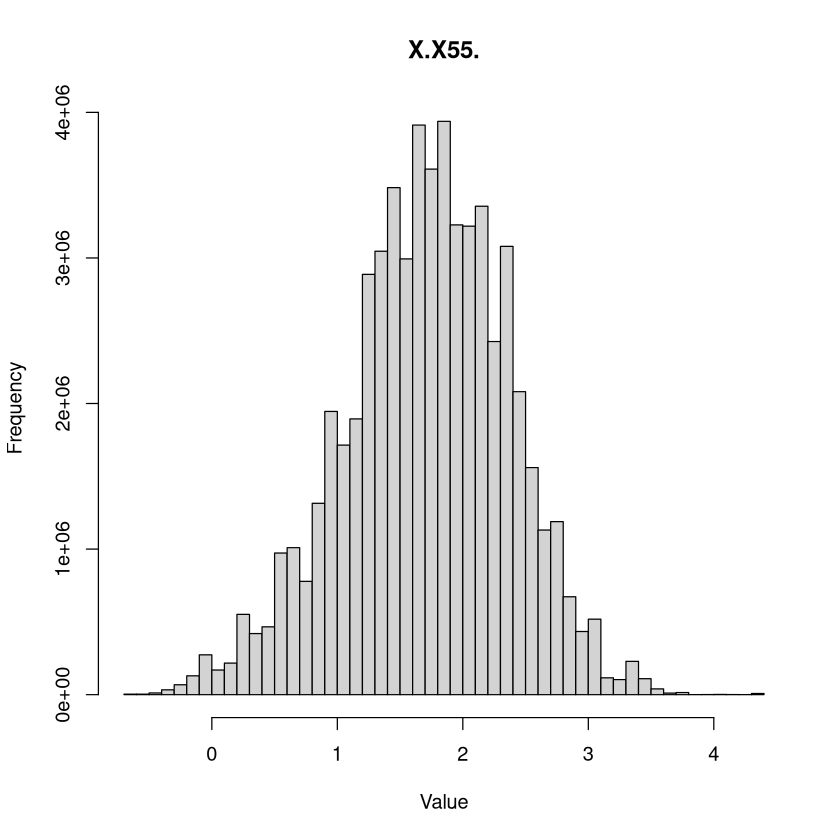

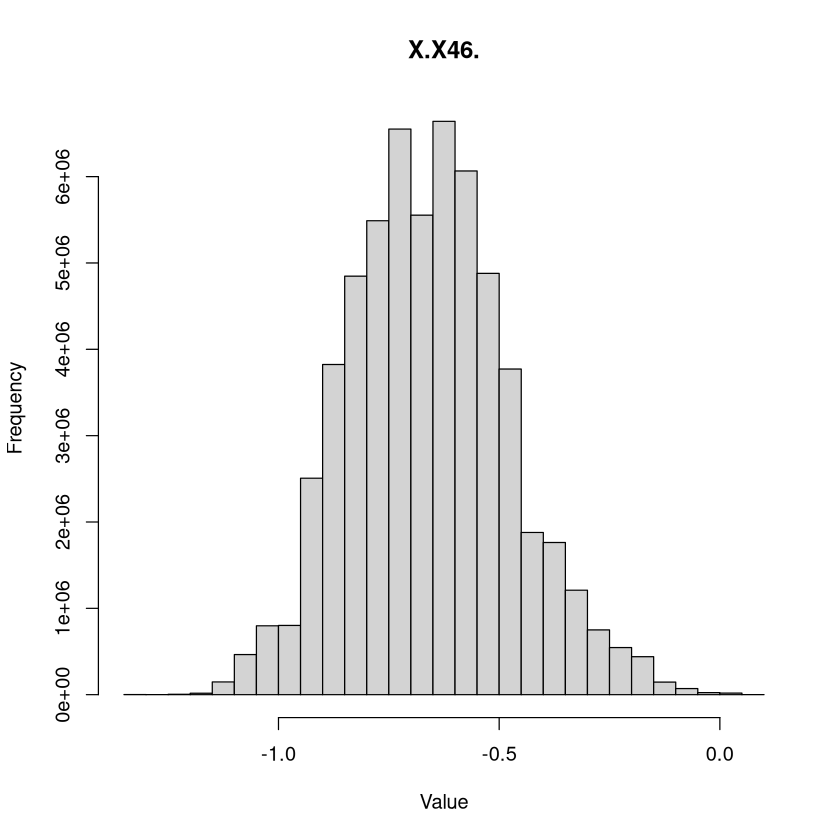

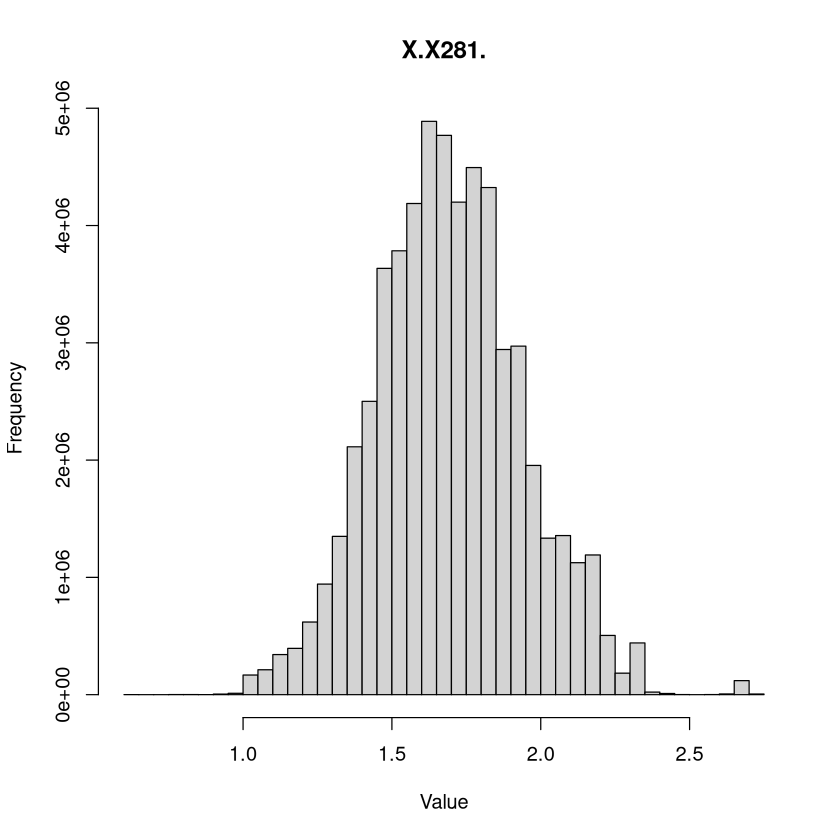

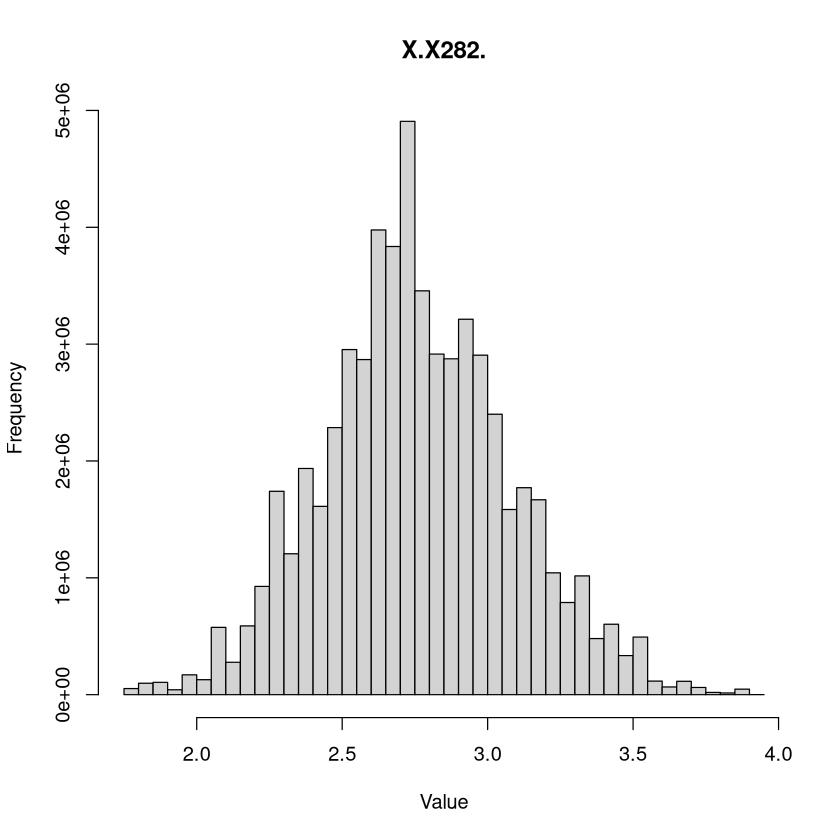

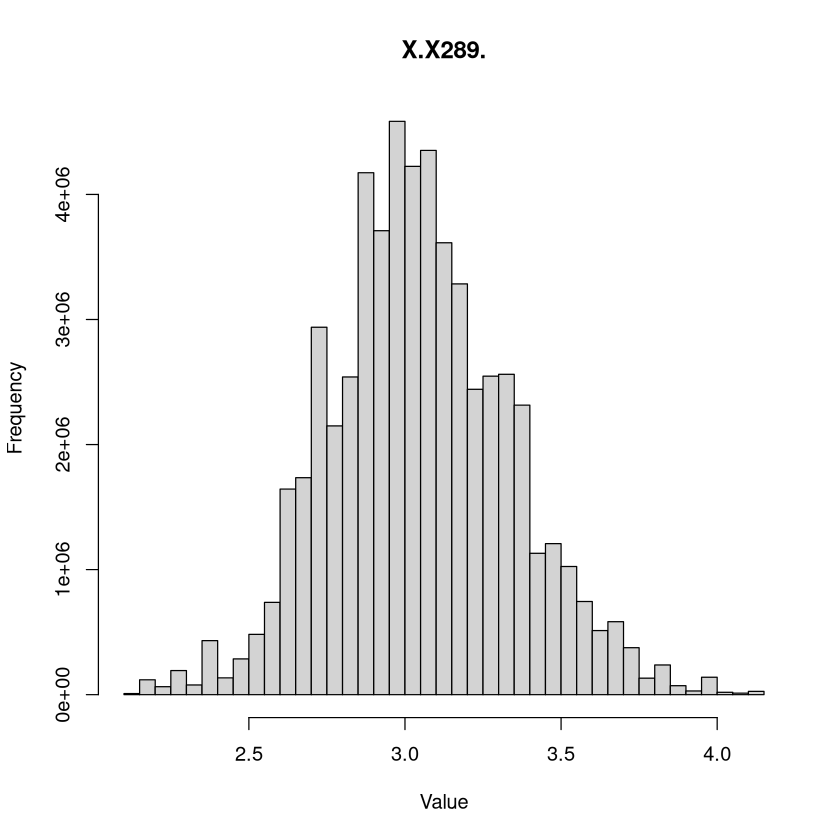

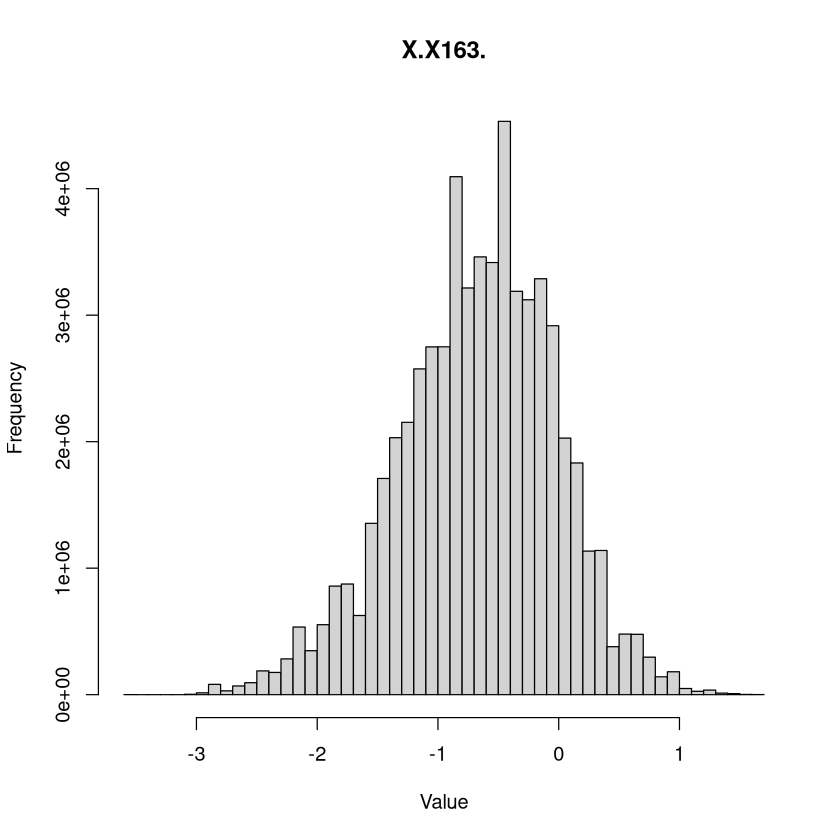

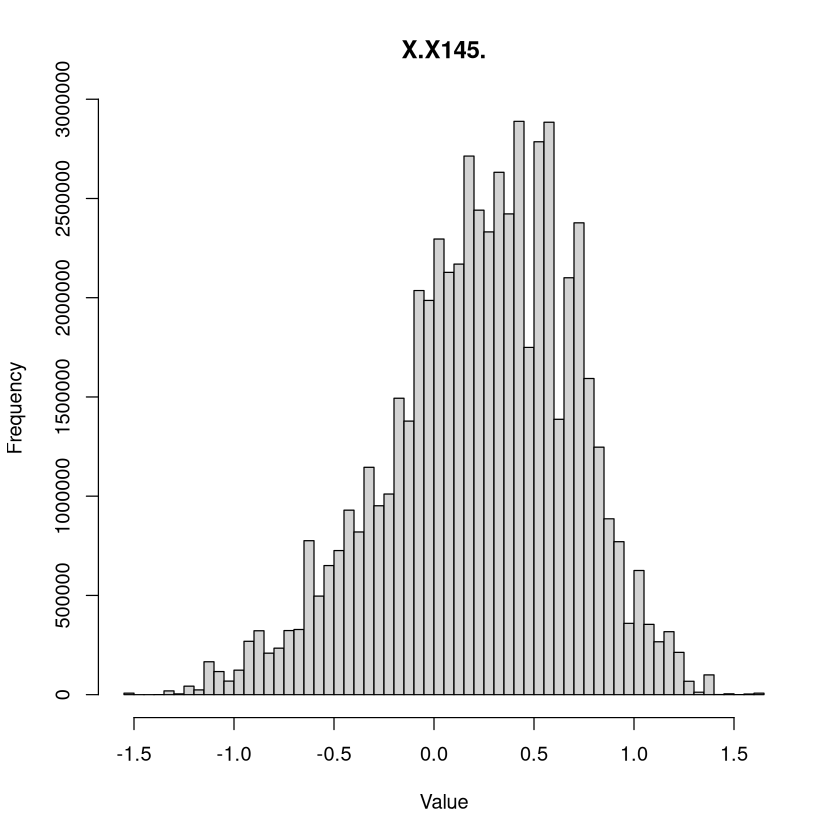

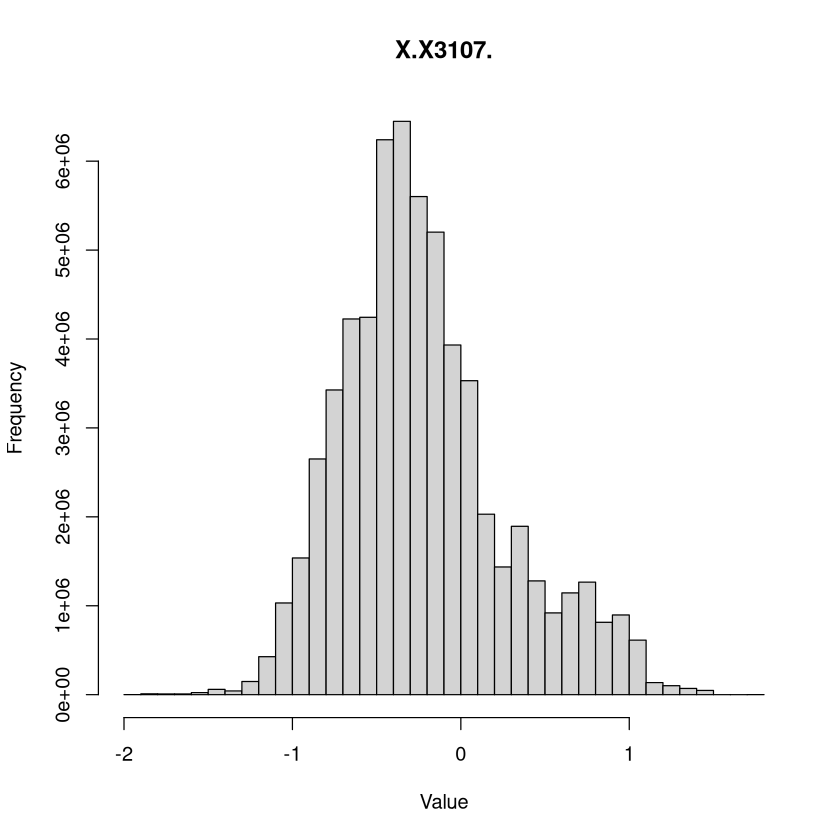

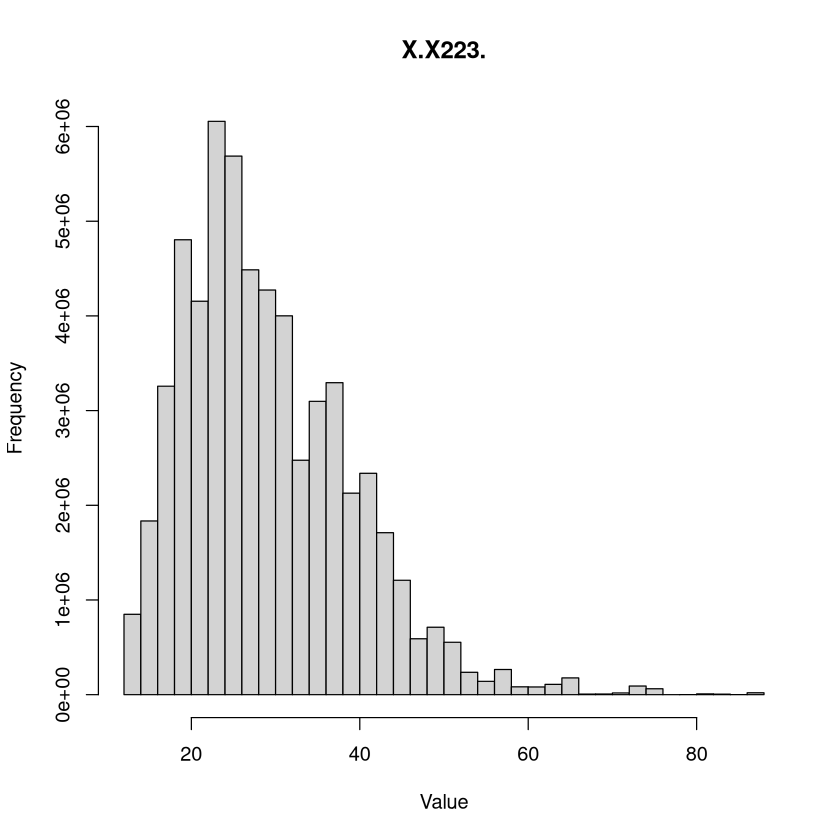

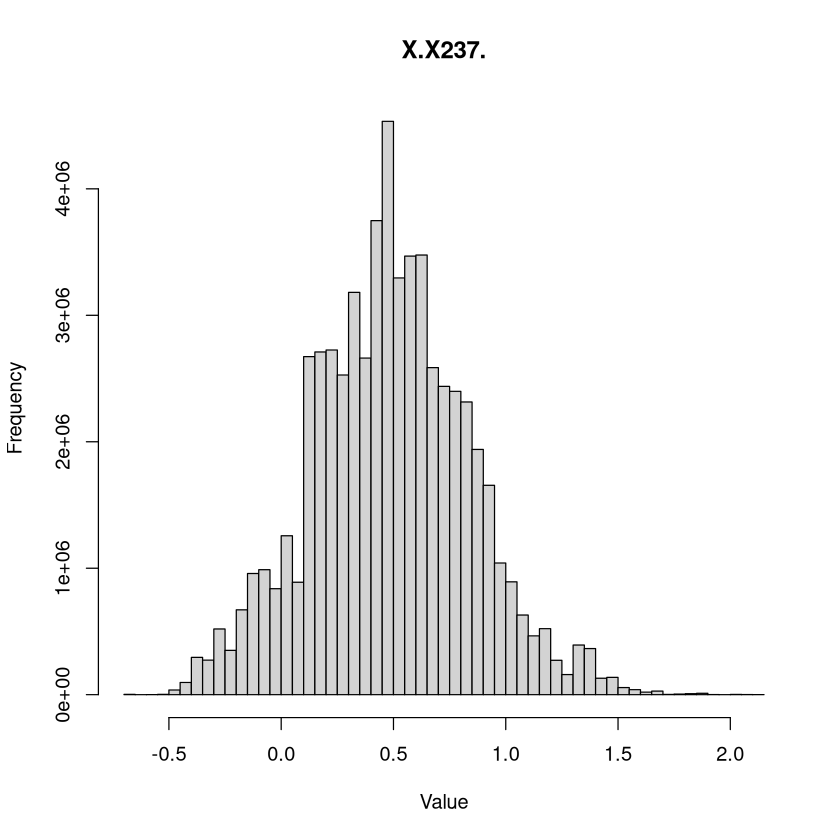

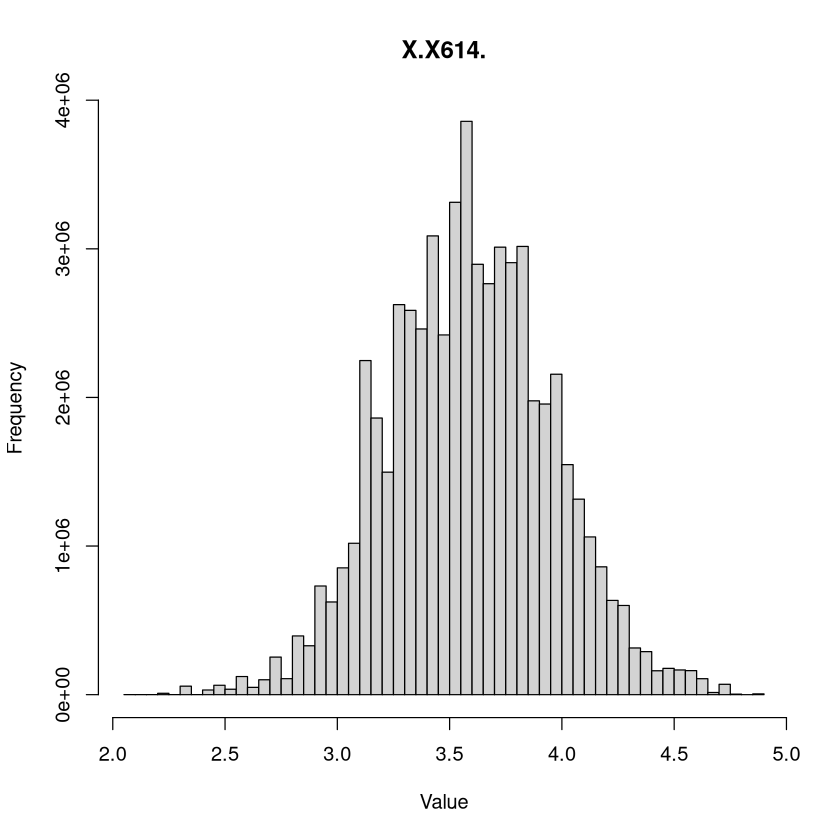

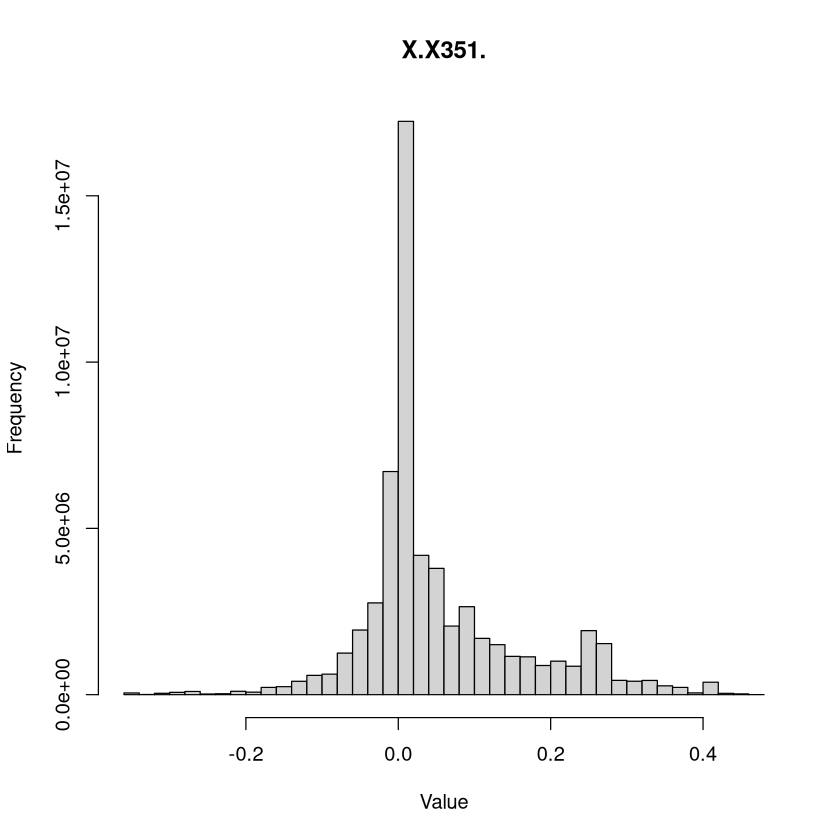

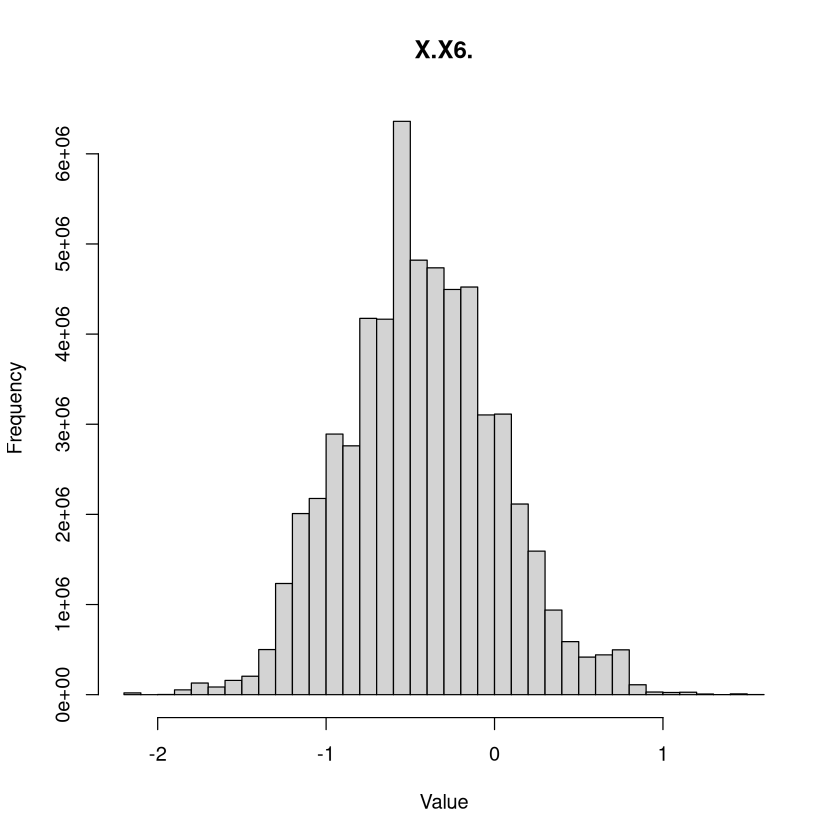

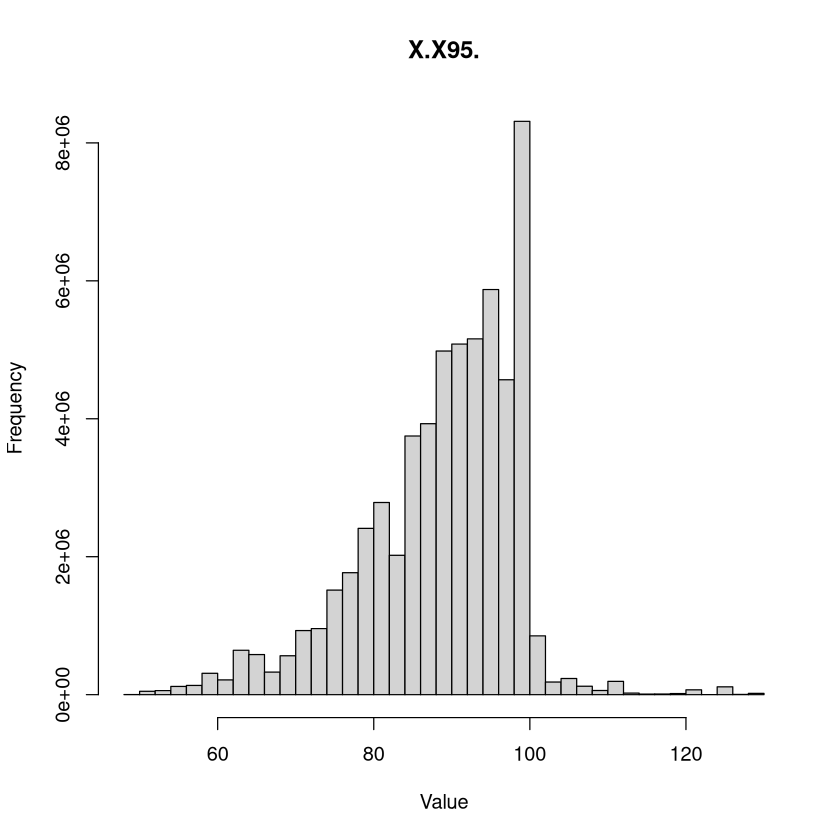

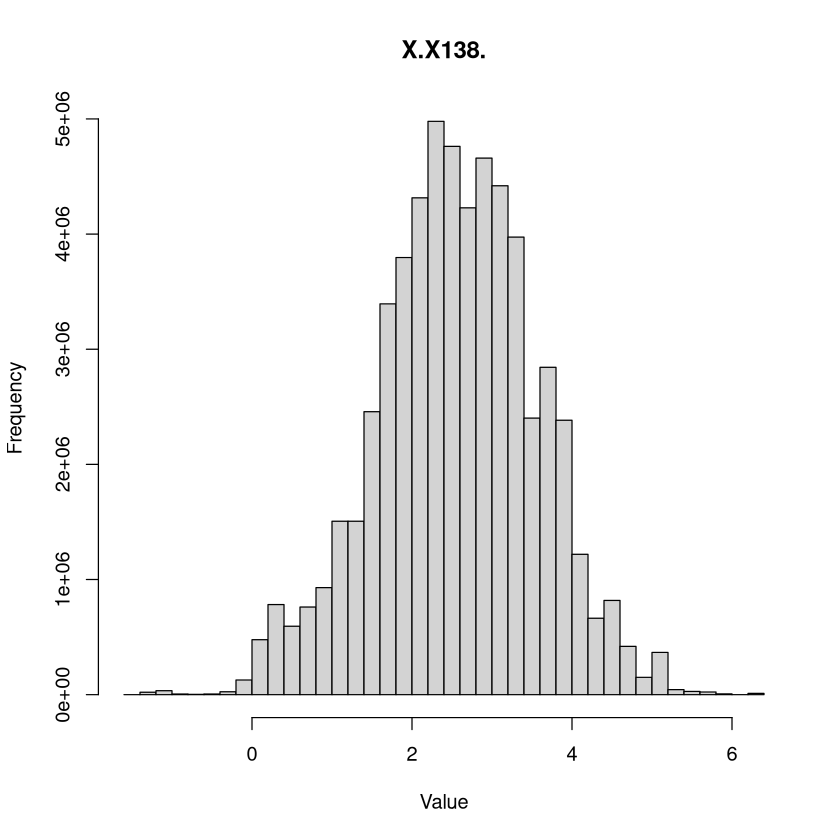

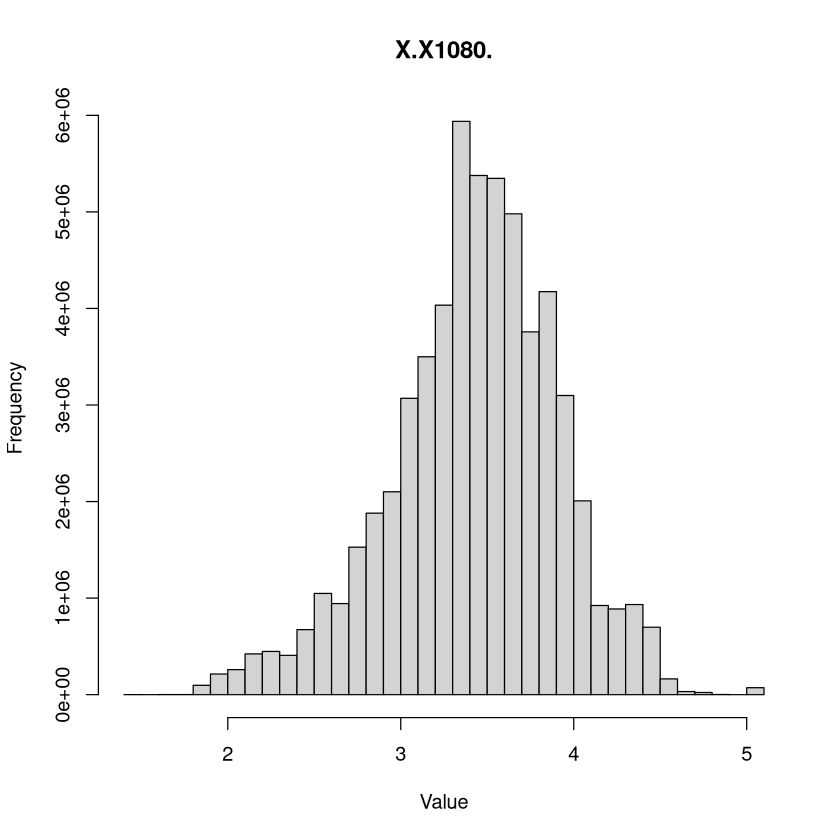

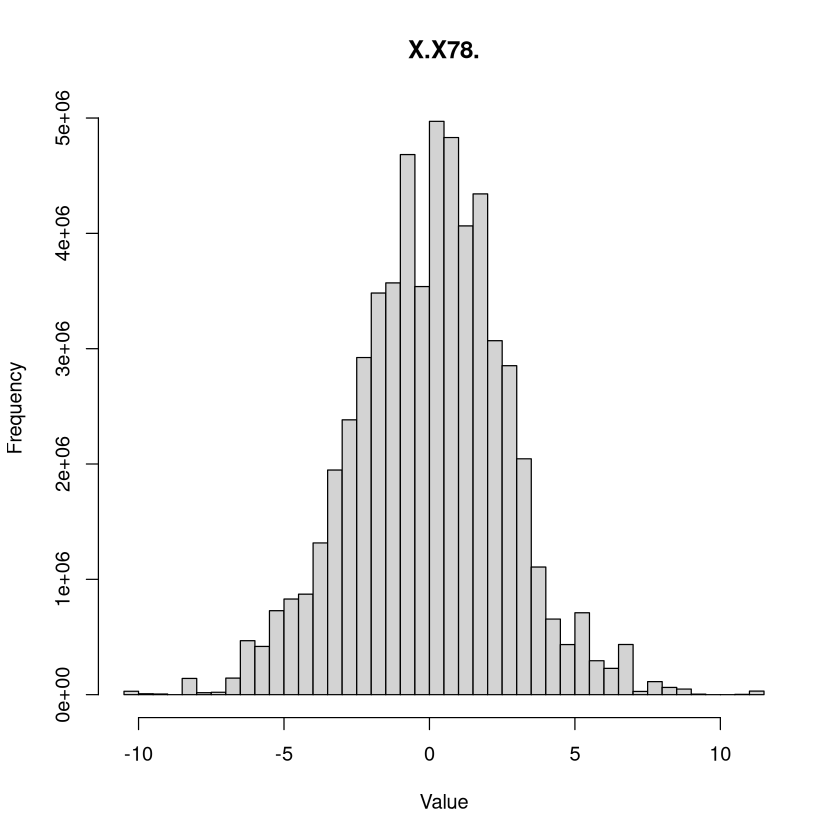

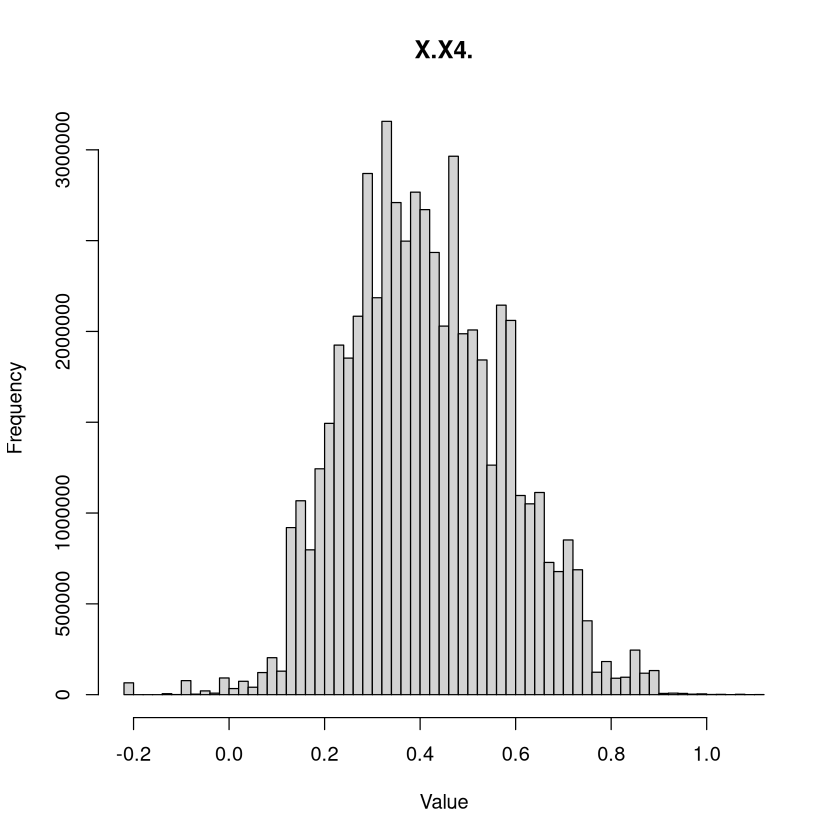

In [14]:
# visualize distrubution historgramm for each glonaf_cols
for (col in glonaf_cols) {
  hist(gbif_try_glonaf[[col]], main = col, xlab = "Value", breaks = 50)
}   

## Seperating wood/non-woody

In [ ]:
# filter for woody species, i.e. woodiness == "woody"
gbif_try_glonaf_woody <- gbif_try_glonaf[woodiness == "woody"]  

# filter for herbaceous species, i.e. woodiness == "non-woody"
gbif_try_glonaf_nonwoody <- gbif_try_glonaf[woodiness == "non-woody"]

In [ ]:
head(gbif_try_glonaf_woody)
head(gbif_try_glonaf_nonwoody)

gbifID,speciesKey,decimalLatitude,decimalLongitude,h3_res3,h3_res4,X.X3117.,X.X14.,X.X50.,X.X146.,⋯,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,most_common_pft,status,woodiness
<int64>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
891018389,2986175,37.81738,-122.03407,832830fffffffff,842830dffffffff,14.198018,22.39489,1.8711526,19.09068,⋯,0.312627914,-0.3875937,90.06101,2.145308,3.249002,-3.0880865,0.7170612,Shrub,native,woody
891018395,2878586,37.93479,-122.15282,832830fffffffff,8428309ffffffff,9.527582,18.02185,1.8542082,25.20681,⋯,0.343334832,0.4460646,75.85665,1.938855,2.372218,-2.1076073,0.5244097,Tree,native,woody
891018400,3039404,37.89495,-121.92952,832830fffffffff,842830dffffffff,4.307864,14.87239,3.4717732,30.36493,⋯,0.201054767,0.5608330,79.49740,2.021147,2.424295,-2.2933259,0.6810611,Shrub,native,woody
891018401,2878384,37.88037,-121.91015,832830fffffffff,842830dffffffff,7.470983,14.70848,1.9751395,30.55207,⋯,0.233454910,0.6202979,87.50078,1.566982,2.710370,-2.7042158,0.7399179,Tree,native,woody
891018525,5361801,37.75597,-122.42299,832830fffffffff,8428309ffffffff,32.867229,27.65699,0.9038989,19.73447,⋯,0.006605481,-1.3075011,81.74584,2.164223,3.428258,-1.5580970,0.3811240,Grass,non-native,woody
891018546,2888711,41.97666,-74.39393,832a16fffffffff,842a169ffffffff,26.667280,21.48583,0.8264085,23.69826,⋯,-0.002084161,-1.3521995,87.12767,3.490928,3.922812,0.0538263,0.3452209,Shrub,native,woody


gbifID,speciesKey,decimalLatitude,decimalLongitude,h3_res3,h3_res4,X.X3117.,X.X14.,X.X50.,X.X146.,⋯,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,most_common_pft,status,woodiness
<int64>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
891018399,2928026,37.16354,-121.48340,832834fffffffff,8428345ffffffff,12.83486,9.708971,0.8664297,NA,⋯,0.059688533,NA,97.96611,NA,3.843915,NA,0.5196287,Grass,native,non-woody
891018402,5298502,38.58038,-123.31329,832831fffffffff,8428311ffffffff,12.68789,17.383079,1.5956363,32.10343,⋯,0.011091186,-0.4158437,81.96427,2.279166,3.588906,1.9502353,0.3792678,Grass,native,non-woody
891018420,3170247,38.86401,-92.30112,832655fffffffff,8426551ffffffff,15.63462,22.277317,1.5056176,26.81873,⋯,-0.022261752,-0.5488086,90.98298,3.012518,3.277295,-1.2609443,0.2986021,Grass,native,non-woody
891018523,7755768,38.24850,-122.13262,832830fffffffff,8428301ffffffff,14.87488,24.322906,1.7187068,19.88473,⋯,0.036468936,-1.0939911,90.36205,2.225252,3.276914,-2.1103301,0.3962590,Grass,native,non-woody
891018527,2890040,38.57299,-122.68964,832830fffffffff,8428303ffffffff,20.84051,22.938056,1.1228202,23.25874,⋯,0.007165869,-0.6220527,87.78239,2.220827,3.561106,-0.7435734,0.2479625,Grass,non-native,non-woody
891018538,2772636,38.57106,-122.68720,832830fffffffff,8428303ffffffff,11.43756,29.581863,2.8824856,20.45306,⋯,0.102089609,NA,NA,1.388793,NA,NA,0.4193848,Grass,native,non-woody


# Aggregate observations to grid-cell averages

In [15]:
library(data.table)

calc_stats <- function(dt, trait_cols, h3_cols = c("h3_res3", "h3_res4")) {
  
  dt <- as.data.table(dt)
  
  all_results <- rbindlist(lapply(h3_cols, function(h3_col) {
  cat("Processing by:", h3_col, "\n")
  
  results <- dt[, {
    
    # Basic counts
    count_all <- sum(status %in% c("native", "non-native"), na.rm = TRUE)
    count_native <- sum(status == "native", na.rm = TRUE)
    count_sp_all <- uniqueN(speciesKey[status %in% c("native", "non-native")], na.rm = TRUE)
    count_sp_native <- uniqueN(speciesKey[status == "native"], na.rm = TRUE)
    
    rec_woody <- sum(woodiness == "woody", na.rm = TRUE)
    rec_nonwoody <- sum(woodiness == "non-woody", na.rm = TRUE)

    perc_woody <- if (.N > 0) round(rec_woody / .N * 100, 2) else NA_real_
    perc_nonwoody <- if (.N > 0) round(rec_nonwoody / .N * 100, 2) else NA_real_
    
    # Trait-wise stats
    trait_stats <- lapply(.SD, function(x) {
    x <- as.numeric(x)
    
    #all_x <- x[!is.na(x)]
    all_x <- x[status %in% c("native", "non-native") & !is.na(x)]
    native_x <- x[status == "native" & !is.na(x)]
    
    # Trimmed means
    if (length(all_x) > 1) {
      all_trim <- all_x[all_x > quantile(all_x, 0.01, na.rm = TRUE) &
              all_x < quantile(all_x, 0.99, na.rm = TRUE)]
    } else all_trim <- all_x
    
    if (length(native_x) > 1) {
      native_trim <- native_x[native_x > quantile(native_x, 0.01, na.rm = TRUE) &
                  native_x < quantile(native_x, 0.99, na.rm = TRUE)]
    } else native_trim <- native_x
    
    mean_all <- round(mean(all_trim, na.rm = TRUE), 3)
    mean_native <- round(mean(native_trim, na.rm = TRUE), 3)
    median_all <- round(median(all_x, na.rm = TRUE), 3)
    median_native <- round(median(native_x, na.rm = TRUE), 3)
    
    percent_change_mean <- if (!is.na(mean_native) && mean_native != 0) {
      round((mean_all - mean_native) / abs(mean_native) * 100, 2)
    } else NA_real_
    
    percent_change_median <- if (!is.na(median_native) && median_native != 0) {
      round((median_all - median_native) / abs(median_native) * 100, 2)
    } else NA_real_
    
    c(
      mean_all = mean_all,
      mean_native = mean_native,
      median_all = median_all,
      median_native = median_native,
      percent_change_mean = percent_change_mean,
      percent_change_median = percent_change_median
    )
    })
    
    c(
    .(count_all, count_native, count_sp_all, count_sp_native, rec_woody, rec_nonwoody,
    perc_woody, perc_nonwoody),
    unlist(trait_stats, recursive = FALSE)
    )
  }, by = h3_col, .SDcols = trait_cols]
  
  # Rename grouping column to a consistent name
  setnames(results, old = h3_col, new = "h3_cell")
  results[, resolution := h3_col]
  
  return(results)
  }), use.names = TRUE, fill = TRUE, idcol = NULL)
  
  return(all_results)
}

# Test loop for res_3 and all dataset
trait_columns <- grep("^X\\.X\\d+\\.", names(gbif_try_glonaf), value = TRUE)

# Define the dataset
dt <- gbif_try_glonaf

# Define the resolution to process
h3_col <- "h3_res3"

cat("\n--- Testing dataset: all ---\n")
cat("   -> Resolution:", h3_col, "\n")

# Run the calculation
result <- calc_stats(dt, trait_columns, h3_cols = h3_col)

# Build the output path
output_file <- paste0(
    "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_",
    h3_col, "_try6_summary_stats_all_CS_log10_woody.csv"
)

# Save to CSV
fwrite(result, output_file, row.names = FALSE, quote = TRUE)
cat("      Saved:", output_file, "\n")



--- Testing dataset: all ---
   -> Resolution: h3_res3 


Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_woody.csv 


In [16]:
dim(gbif_try_glonaf)

[1] 64141358       46

## Loop over all versions (woodiness and h3_res)

In [18]:
library(data.table)

calc_stats <- function(dt, trait_cols, h3_cols = c("h3_res3", "h3_res4")) {
  
  dt <- as.data.table(dt)
  
  all_results <- rbindlist(lapply(h3_cols, function(h3_col) {
  cat("Processing by:", h3_col, "\n")
  
  results <- dt[, {
    
    # Basic counts
    count_all <- sum(status %in% c("native", "non-native"), na.rm = TRUE)
    count_native <- sum(status == "native", na.rm = TRUE)
    count_sp_all <- uniqueN(speciesKey[status %in% c("native", "non-native")], na.rm = TRUE)
    count_sp_native <- uniqueN(speciesKey[status == "native"], na.rm = TRUE)
    
    # Trait-wise stats
    trait_stats <- lapply(.SD, function(x) {
    x <- as.numeric(x)
    
    #all_x <- x[!is.na(x)]
    all_x <- x[status %in% c("native", "non-native") & !is.na(x)]
    native_x <- x[status == "native" & !is.na(x)]
    
    # Trimmed means
    if (length(all_x) > 1) {
      all_trim <- all_x[all_x > quantile(all_x, 0.01, na.rm = TRUE) &
              all_x < quantile(all_x, 0.99, na.rm = TRUE)]
    } else all_trim <- all_x
    
    if (length(native_x) > 1) {
      native_trim <- native_x[native_x > quantile(native_x, 0.01, na.rm = TRUE) &
                  native_x < quantile(native_x, 0.99, na.rm = TRUE)]
    } else native_trim <- native_x
    
    mean_all <- round(mean(all_trim, na.rm = TRUE), 3)
    mean_native <- round(mean(native_trim, na.rm = TRUE), 3)
    median_all <- round(median(all_x, na.rm = TRUE), 3)
    median_native <- round(median(native_x, na.rm = TRUE), 3)
    
    percent_change_mean <- if (!is.na(mean_native) && mean_native != 0) {
      round((mean_all - mean_native) / abs(mean_native) * 100, 2)
    } else NA_real_
    
    percent_change_median <- if (!is.na(median_native) && median_native != 0) {
      round((median_all - median_native) / abs(median_native) * 100, 2)
    } else NA_real_
    
    c(
      mean_all = mean_all,
      mean_native = mean_native,
      median_all = median_all,
      median_native = median_native,
      percent_change_mean = percent_change_mean,
      percent_change_median = percent_change_median
    )
    })
    
    c(
    .(count_all, count_native, count_sp_all, count_sp_native),
    unlist(trait_stats, recursive = FALSE)
    )
  }, by = h3_col, .SDcols = trait_cols]
  
  # Rename grouping column to a consistent name
  setnames(results, old = h3_col, new = "h3_cell")
  results[, resolution := h3_col]
  
  return(results)
  }), use.names = TRUE, fill = TRUE, idcol = NULL)
  
  return(all_results)
}


In [19]:
# Define datasets
datasets <- list(
    all = gbif_try_glonaf,
    woody = gbif_try_glonaf_woody,
    nonwoody = gbif_try_glonaf_nonwoody
)

# Define the resolutions to process
h3_cols <- c("h3_res3", "h3_res4")

# Loop over datasets and resolutions
for (name in names(datasets)) {
    dt <- datasets[[name]]
    cat("\n--- Testing dataset:", name, "---\n")
    
    for (h3_col in h3_cols) {
        cat("   -> Resolution:", h3_col, "\n")
        
        # Run the calculation
        result <- calc_stats(dt, trait_columns, h3_cols = h3_col)
        
        # Build the output path
        output_file <- paste0(
            "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_",
            h3_col, "_try6_summary_stats_", name, "_CS.csv"
        )
        
        # Save to CSV
        fwrite(result, output_file, row.names = FALSE, quote = TRUE)
        cat("      Saved:", output_file, "\n")
    }
}



--- Testing dataset: all ---
   -> Resolution: h3_res3 
Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS.csv 
   -> Resolution: h3_res4 
Processing by: h3_res4 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res4_try6_summary_stats_all_CS.csv 

--- Testing dataset: woody ---
   -> Resolution: h3_res3 
Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_woody_CS.csv 
   -> Resolution: h3_res4 
Processing by: h3_res4 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res4_try6_summary_stats_woody_CS.csv 

--- Testing dataset: nonwoody ---
   -> Resolution: h3_res3 
Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_nonwoody_CS.csv 
   -> Resolution: h3_res4 
Processing by: h3_res4 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res4_try6_summary_stats_nonwoody_CS.csv 


## Orinial script for only res_3

In [ ]:
asdglj

In [ ]:
# calculate summary statistics function

calc_stats <- function(dt, trait_cols) {

  
  # Calculate statistics
  results <- dt[, c(.(
    count_all = .N,
    count_native = sum(status == "native", na.rm = TRUE),
    count_sp_all = uniqueN(speciesKey),
    count_sp_native = uniqueN(speciesKey[status == "native"])
  ),

  
  unlist(lapply(.SD, function(x) {
    

    x <- as.numeric(x)  # Ensure numeric
 
    native_x <- x[status == "native"]
    all_x <- x
    
    # Remove NAs
    native_x <- native_x[!is.na(native_x)]
    all_x <- all_x[!is.na(all_x)]
    
    n_native <- as.numeric(length(native_x))
    n_all <- as.numeric(length(all_x))

    if (n_native > 10 & n_all > 10) {
      test <- wilcox.test(native_x, all_x, exact = FALSE) # non-parametric test
      U <- as.numeric(test$statistic)

      r <- 1 - (2 * U) / (n_native * n_all)  # Rank-Biserial Correlation as effect size
      if (n_native * n_all > .Machine$integer.max) {
  warning("Potential overflow in effect size calc: large n_native * n_all")
}

      p_value <- test$p.value
    } else {
      r <- NA
      p_value <- NA
    }
    
    return(c(
      mean_all = round(mean(all_x[all_x > quantile(all_x, 0.01, na.rm = TRUE) & all_x < quantile(all_x, 0.99, na.rm = TRUE)], na.rm = TRUE), 3),
      mean_native = round(mean(native_x[native_x > quantile(native_x, 0.01, na.rm = TRUE) & native_x < quantile(native_x, 0.99, na.rm = TRUE)], na.rm = TRUE), 3),
      median_all = round(median(all_x, na.rm = TRUE), 3),
      median_native = round(median(native_x, na.rm = TRUE),3),
      percent_change_mean = ifelse(mean_native != 0,
                              round((mean_all - mean_native) / abs(mean_native)*100, 2),
                              NA),
      percent_change_median = ifelse(median_native != 0,
                              round((median_all - median_native) / abs(median_native)*100, 2),
                              NA),
      p_value = p_value,
      rank_biserial_r = r
    ))
  }), recursive = FALSE)), by = h3_res3, .SDcols = trait_cols]
  
  # Apply Benjamini-Hochberg correction for multiple testing
  #results[, p_value_adjusted := p.adjust(p_value, method = "BH")]

  
  return(results)
}

# Ensure trait columns are correctly identified
trait_columns <- grep("^X\\.X\\d+\\.", names(gbif_try_glonaf), value = TRUE)

# Run the function on the downsampled data
# Initialize a list to store results for each dataset
datasets <- list(
  all = gbif_try_glonaf,
  woody = gbif_try_glonaf_woody,
  nonwoody = gbif_try_glonaf_nonwoody
)

# Loop over each dataset and calculate statistics
results_list <- lapply(names(datasets), function(name) {
  cat("Processing:", name, "\n")
  result <- calc_stats(datasets[[name]], trait_columns)
  
  # Save the results to CSV
  output_file <- paste0("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_res3_try6_s1_5000_summary_stats_", name, ".csv")
  fwrite(result, output_file, row.names = FALSE, quote = TRUE)
  
  return(result)
})





Processing: all 
Processing: woody 
Processing: nonwoody 
